<a href="https://colab.research.google.com/github/santyxd3000/Fault-Detection-Classification-SD/blob/main/Fault_Anomaly_Labeling.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **FAULT AND ANOMALY - MANUAL LABELING**

Santiago Pardo Morales

In [144]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import ipywidgets as widgets
from IPython.display import display
import datetime
import scipy
sns.set()
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import pairwise_distances_argmin_min
from sklearn.ensemble import IsolationForest
from sklearn.svm import OneClassSVM
import io
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import make_scorer, f1_score
from sklearn import model_selection
from sklearn.datasets import make_classification
from sklearn.model_selection import ParameterGrid
from sklearn.neighbors import LocalOutlierFactor
from sklearn.neural_network import MLPRegressor
from sklearn.metrics import mean_squared_error
from sklearn.neural_network import MLPRegressor
from scipy.optimize import curve_fit

In [145]:
ae_df = pd.read_csv('df_with_anomalies_neurons3.csv',sep=';')
iqr_df = pd.read_csv('statistical_df_with_anomalies.csv',sep=';')
#sensor = pd.read_csv('sensor_data.csv',sep=';').dropna()

In [146]:
#ae_df = pd.merge(ae_df1, sensor, how="inner", on=["Timestamp"])

In [147]:
anomaly_iqr = iqr_df[iqr_df['Anomaly']==1]
no_anomaly_iqr = iqr_df[iqr_df['Anomaly']==0]

In [148]:
anomaly_ae = ae_df[ae_df['Anomaly']==1]
no_anomaly_ae = ae_df[ae_df['Anomaly']==0]

*CORRECCIÓN EVALUACIÓN DE MODELO*

In [149]:
stat_training_anomalies = iqr_df[iqr_df['Timestamp']<'2021-09-03']
stat_testing_anomalies = iqr_df[iqr_df['Timestamp']>'2021-09-03']

In [150]:
ml_training_anomalies = ae_df[ae_df['Timestamp']<'2021-09-03']
ml_testing_anomalies = ae_df[ae_df['Timestamp']>'2021-09-03']

In [151]:
iqr_train = np.array(stat_training_anomalies['Anomaly'])
iqr_test = np.array(stat_testing_anomalies['Anomaly'])
ml_train = np.array(ml_training_anomalies['Anomaly'])
ml_test = np.array(ml_testing_anomalies['Anomaly'])

*ENTRENAMIENTO*

In [152]:
from sklearn.metrics import accuracy_score
from sklearn.metrics import f1_score
from sklearn.metrics import precision_score
from sklearn.metrics import recall_score
from sklearn.metrics import confusion_matrix
from sklearn.metrics import ConfusionMatrixDisplay


accuracy = accuracy_score(ml_train, iqr_train)
precision = precision_score(ml_train, iqr_train)
f1_score = f1_score(ml_train, iqr_train)
recall = recall_score(ml_train, iqr_train)

print("Precision: "+ str(precision))
print("Accuracy: "+ str(accuracy))
print("F1_Score: "+ str(f1_score))
print("Recall: "+ str(recall))

Precision: 0.8845464725643897
Accuracy: 0.9148929926835948
F1_Score: 0.6448426466386383
Recall: 0.5073543580191406


In [153]:
#Make Confusion Matrix and Evaluate TP, TN, FN, FP
def compute_tp_tn_fn_fp(y_act, y_pred):
    tp = sum((y_act == 1) & (y_pred == 1))
    tn = sum((y_act == 0) & (y_pred == 0))
    fn = sum((y_act == 1) & (y_pred == 0))
    fp = sum((y_act == 0) & (y_pred == 1))
    return tp, tn, fn, fp

tp,tn,fn,fp = compute_tp_tn_fn_fp(iqr_train, ml_train)
print("Number of TP: "+str(tp))
print("Number of TN: "+str(tn))
print("Number of FP: "+str(fp))
print("Number of FN: "+str(fn))

Number of TP: 7899
Number of TN: 85636
Number of FP: 7670
Number of FN: 1031


Text(0.5, 1.0, 'Confusion Matrix for LSTM Autoencoder - Train Data')

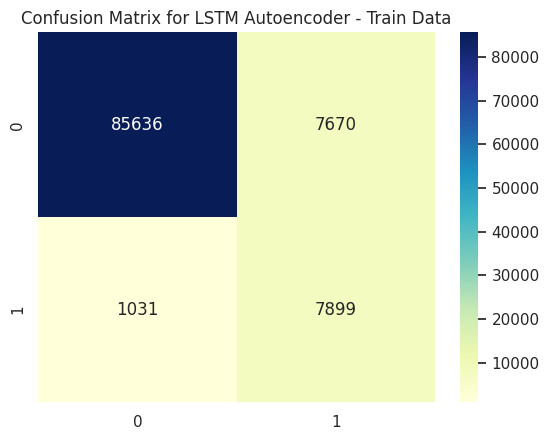

In [154]:
cm_train = confusion_matrix(iqr_train, ml_train)
sns.heatmap(cm_train,annot=True, fmt='g',cmap='YlGnBu')
# Set the axis labels and title
plt.title('Confusion Matrix for LSTM Autoencoder - Train Data')

*PRUEBA*

In [155]:
from sklearn.metrics import accuracy_score
from sklearn.metrics import f1_score
from sklearn.metrics import precision_score
from sklearn.metrics import recall_score
from sklearn.metrics import confusion_matrix
from sklearn.metrics import ConfusionMatrixDisplay


accuracy = accuracy_score(ml_test, iqr_test)
precision = precision_score(ml_test, iqr_test)
f1_score = f1_score(ml_test, iqr_test)
recall = recall_score(ml_test, iqr_test)

print("Precision: "+ str(precision))
print("Accuracy: "+ str(accuracy))
print("F1_Score: "+ str(f1_score))
print("Recall: "+ str(recall))

Precision: 0.9989478276490363
Accuracy: 0.9748141688468087
F1_Score: 0.9846581926263202
Recall: 0.9707716095565864


In [156]:
tp,tn,fn,fp = compute_tp_tn_fn_fp(iqr_test, ml_test)
print("Number of TP: "+str(tp))
print("Number of TN: "+str(tn))
print("Number of FP: "+str(fp))
print("Number of FN: "+str(fn))

Number of TP: 38926
Number of TN: 8023
Number of FP: 1172
Number of FN: 41


Text(0.5, 1.0, 'Confusion Matrix for LSTM Autoencoder - Test Data')

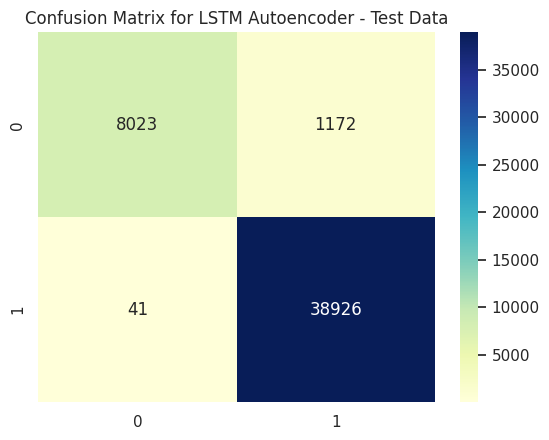

In [157]:
cm_test = confusion_matrix(iqr_test, ml_test)
sns.heatmap(cm_test,annot=True, fmt='g',cmap='YlGnBu')
# Set the axis labels and title
plt.title('Confusion Matrix for LSTM Autoencoder - Test Data')

In [158]:
anomaly_iqr_train = stat_training_anomalies[stat_training_anomalies['Anomaly']==1]
no_anomaly_iqr_train = stat_training_anomalies[stat_training_anomalies['Anomaly']==0]

In [159]:
anomaly_iqr_test = stat_testing_anomalies[stat_testing_anomalies['Anomaly']==1]
no_anomaly_iqr_test = stat_testing_anomalies[stat_testing_anomalies['Anomaly']==0]

In [160]:
anomaly_ae_train = ml_training_anomalies[ml_training_anomalies['Anomaly']==1]
no_anomaly_ae_train = ml_training_anomalies[ml_training_anomalies['Anomaly']==0]

In [161]:
anomaly_ae_test = ml_testing_anomalies[ml_testing_anomalies['Anomaly']==1]
no_anomaly_ae_test = ml_testing_anomalies[ml_testing_anomalies['Anomaly']==0]

## **COMPARACIÓN FINAL CON MÉTODO ESTADÍSTICO**

*Entrenamiento*

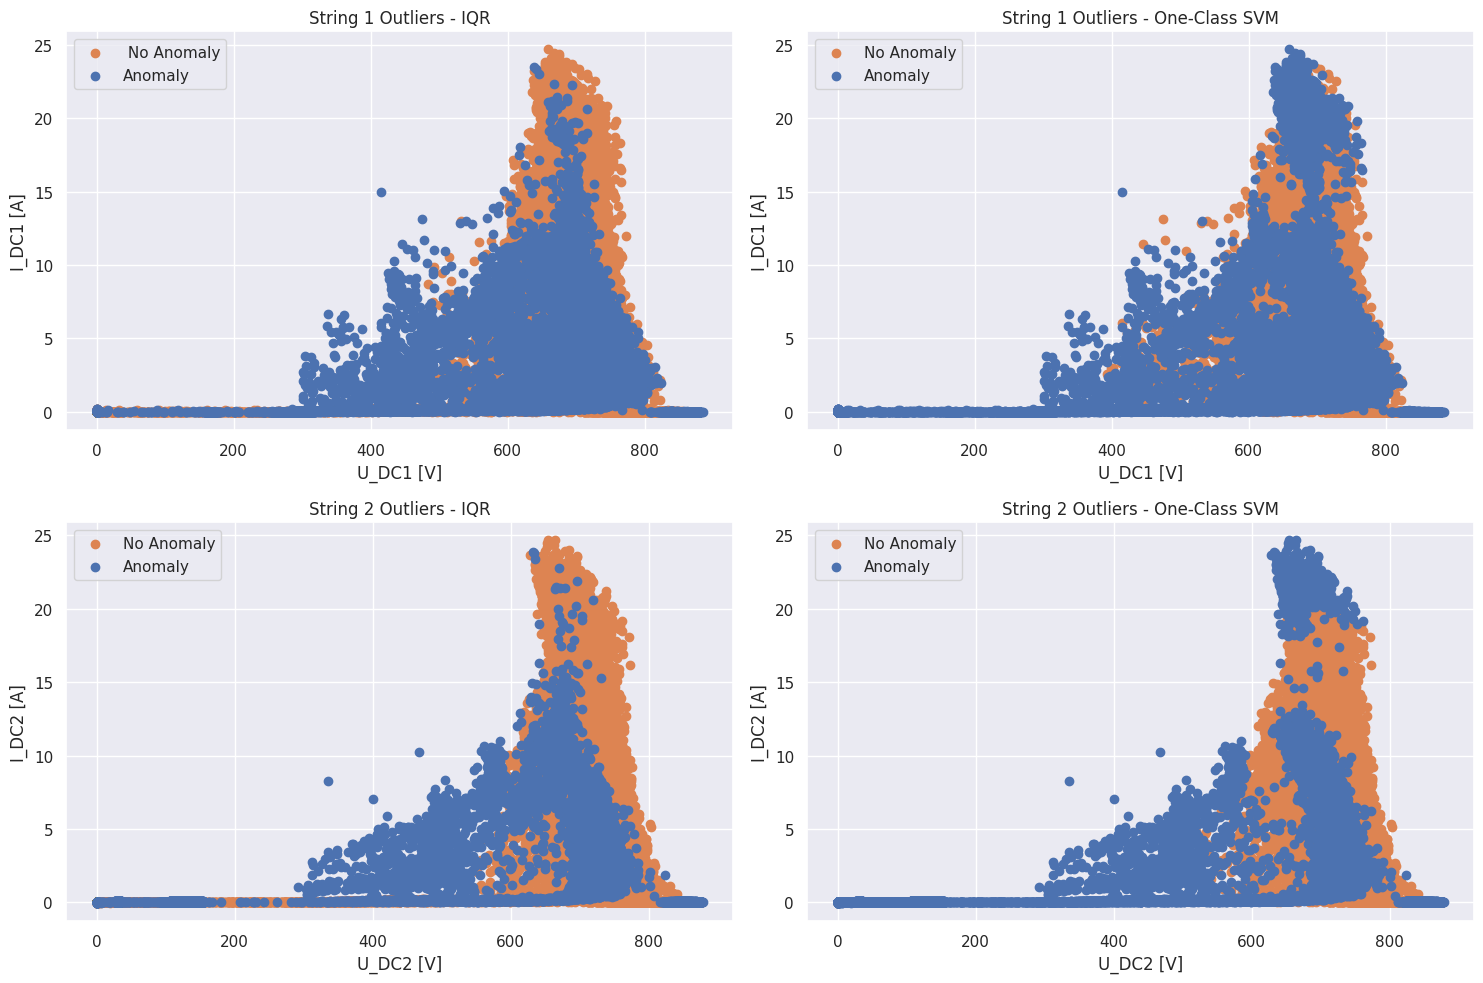

In [162]:
#STRING1

# Gráfico 1
plt.figure(figsize=(15, 10))

# Gráfico 1
plt.subplot(2,2,1)
plt.scatter(no_anomaly_iqr['U_DC1'], no_anomaly_iqr['I_DC1'], label=' No Anomaly', color='#dd8452')
plt.scatter(anomaly_iqr['U_DC1'], anomaly_iqr['I_DC1'], label='Anomaly', color= '#4c72b0')
plt.xlabel('U_DC1 [V]')
plt.ylabel('I_DC1 [A]')
plt.legend()
plt.title('String 1 Outliers - IQR')

# Gráfico 2
plt.subplot(2,2,2)
plt.scatter(no_anomaly_ae['U_DC1'], no_anomaly_ae['I_DC1'], label='No Anomaly',color='#dd8452')
plt.scatter(anomaly_ae['U_DC1'], anomaly_ae['I_DC1'], label='Anomaly',color= '#4c72b0')
plt.xlabel('U_DC1 [V]')
plt.ylabel('I_DC1 [A]')
plt.legend()
plt.title('String 1 Outliers - One-Class SVM')

plt.subplot(2,2,3)
plt.scatter(no_anomaly_iqr['U_DC2'], no_anomaly_iqr['I_DC2'], label='No Anomaly',color='#dd8452')
plt.scatter(anomaly_iqr['U_DC2'], anomaly_iqr['I_DC2'], label='Anomaly',color= '#4c72b0')
plt.xlabel('U_DC2 [V]')
plt.ylabel('I_DC2 [A]')
plt.legend()
plt.title('String 2 Outliers - IQR')

# Gráfico 2
plt.subplot(2,2,4)
plt.scatter(no_anomaly_ae['U_DC2'], no_anomaly_ae['I_DC2'], label='No Anomaly',color='#dd8452')
plt.scatter(anomaly_ae['U_DC2'], anomaly_ae['I_DC2'], label='Anomaly',color= '#4c72b0')
plt.xlabel('U_DC2 [V]')
plt.ylabel('I_DC2 [A]')
plt.legend()
plt.title('String 2 Outliers - One-Class SVM')



# Ajustes de diseño
plt.tight_layout()
plt.show()

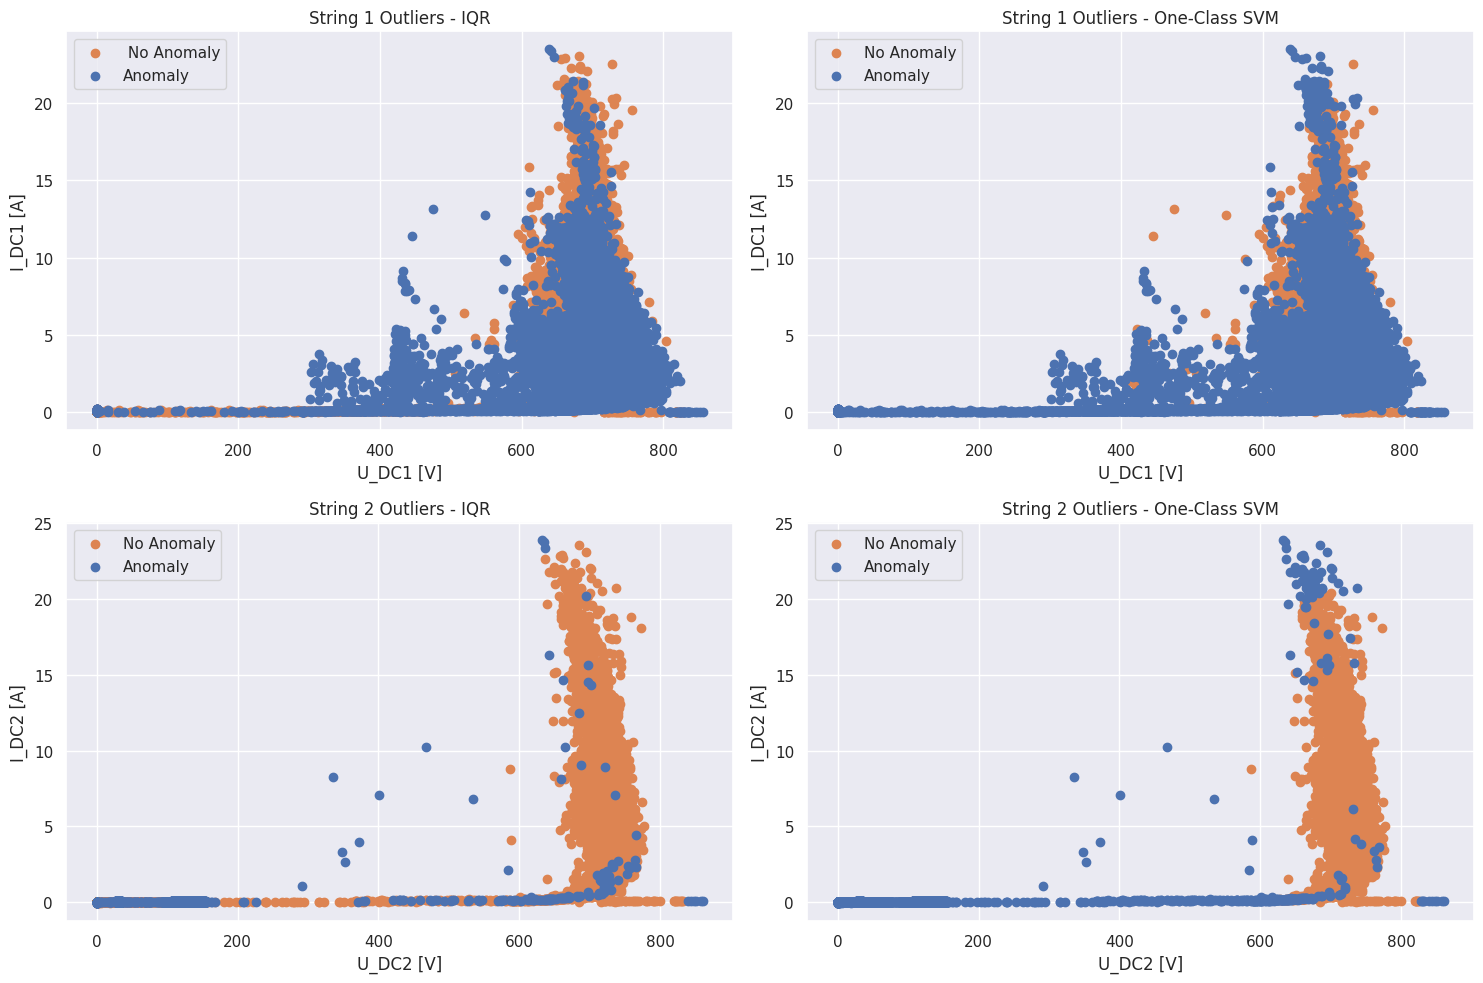

In [60]:
#STRING1

# Gráfico 1
plt.figure(figsize=(15, 10))

# Gráfico 1
plt.subplot(2,2,1)
plt.scatter(no_anomaly_iqr_test['U_DC1'], no_anomaly_iqr_test['I_DC1'], label=' No Anomaly',color='#dd8452')
plt.scatter(anomaly_iqr_test['U_DC1'], anomaly_iqr_test['I_DC1'], label='Anomaly',color= '#4c72b0')
plt.xlabel('U_DC1 [V]')
plt.ylabel('I_DC1 [A]')
plt.legend()
plt.title('String 1 Outliers - IQR')

# Gráfico 2
plt.subplot(2,2,2)
plt.scatter(no_anomaly_ae_test['U_DC1'], no_anomaly_ae_test['I_DC1'], label='No Anomaly',color='#dd8452')
plt.scatter(anomaly_ae_test['U_DC1'], anomaly_ae_test['I_DC1'], label='Anomaly',color= '#4c72b0')
plt.xlabel('U_DC1 [V]')
plt.ylabel('I_DC1 [A]')
plt.legend()
plt.title('String 1 Outliers - One-Class SVM')

plt.subplot(2,2,3)
plt.scatter(no_anomaly_iqr_test['U_DC2'], no_anomaly_iqr_test['I_DC2'], label='No Anomaly',color='#dd8452')
plt.scatter(anomaly_iqr_test['U_DC2'], anomaly_iqr_test['I_DC2'], label='Anomaly',color= '#4c72b0')
plt.xlabel('U_DC2 [V]')
plt.ylabel('I_DC2 [A]')
plt.legend()
plt.title('String 2 Outliers - IQR')

# Gráfico 2
plt.subplot(2,2,4)
plt.scatter(no_anomaly_ae_test['U_DC2'], no_anomaly_ae_test['I_DC2'], label='No Anomaly',color='#dd8452')
plt.scatter(anomaly_ae_test['U_DC2'], anomaly_ae_test['I_DC2'], label='Anomaly',color= '#4c72b0')
plt.xlabel('U_DC2 [V]')
plt.ylabel('I_DC2 [A]')
plt.legend()
plt.title('String 2 Outliers - One-Class SVM')



# Ajustes de diseño
plt.tight_layout()
plt.show()

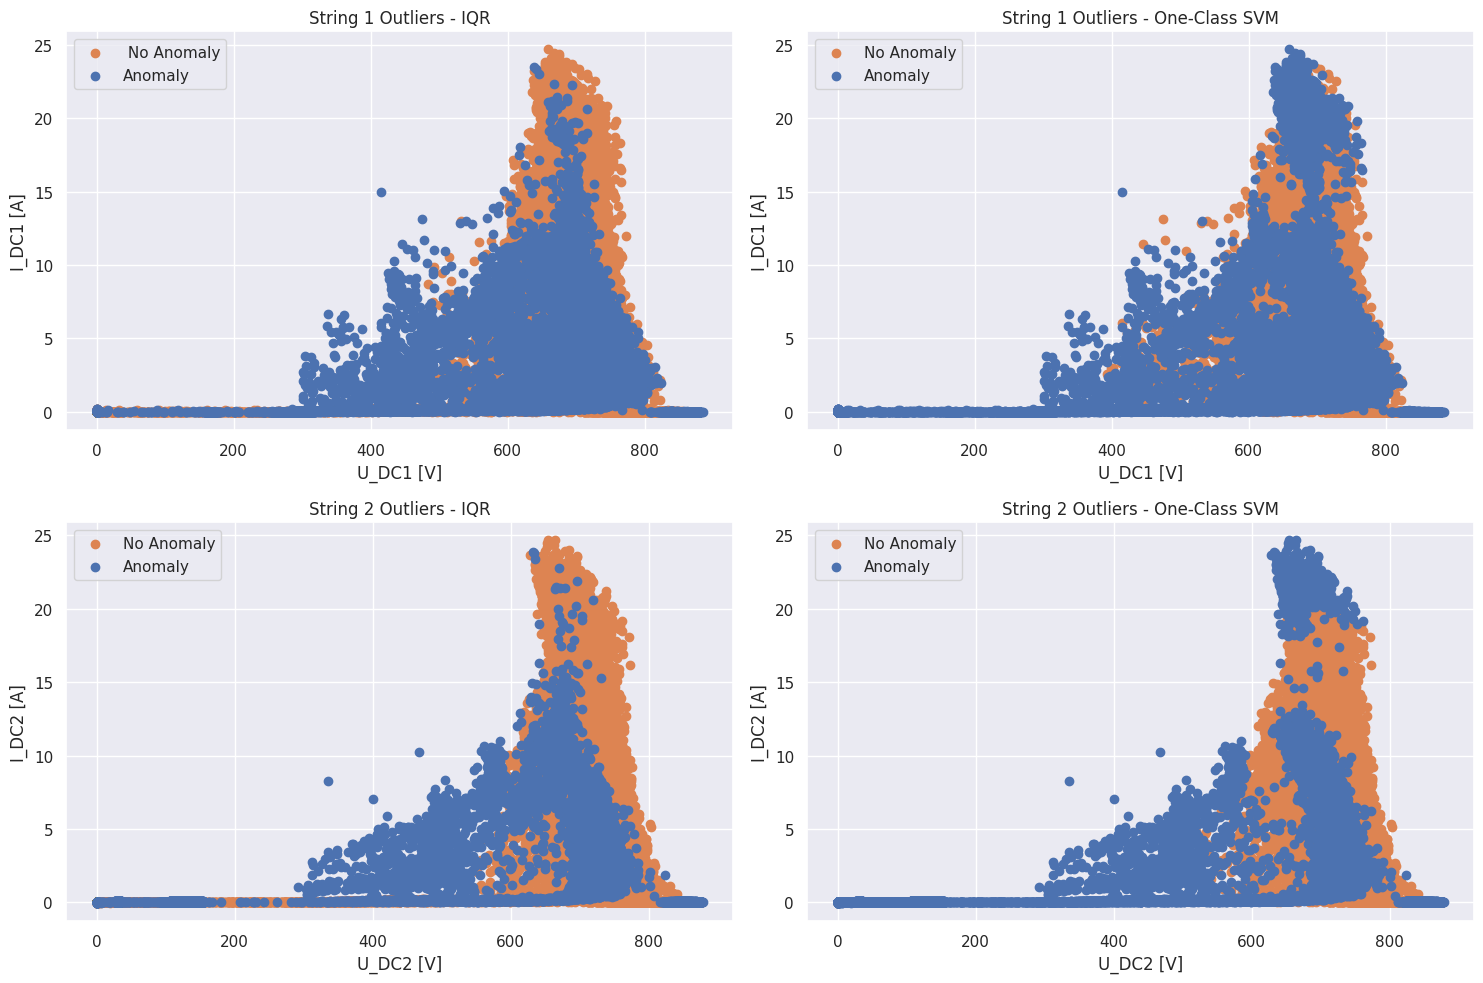

In [62]:
#STRING1

# Gráfico 1
plt.figure(figsize=(15, 10))

# Gráfico 1
plt.subplot(2,2,1)
plt.scatter(no_anomaly_iqr['U_DC1'], no_anomaly_iqr['I_DC1'], label=' No Anomaly',color='#dd8452')
plt.scatter(anomaly_iqr['U_DC1'], anomaly_iqr['I_DC1'], label='Anomaly',color= '#4c72b0')
plt.xlabel('U_DC1 [V]')
plt.ylabel('I_DC1 [A]')
plt.legend()
plt.title('String 1 Outliers - IQR')

# Gráfico 2
plt.subplot(2,2,2)
plt.scatter(no_anomaly_ae['U_DC1'], no_anomaly_ae['I_DC1'], label='No Anomaly',color='#dd8452')
plt.scatter(anomaly_ae['U_DC1'], anomaly_ae['I_DC1'], label='Anomaly',color= '#4c72b0')
plt.xlabel('U_DC1 [V]')
plt.ylabel('I_DC1 [A]')
plt.legend()
plt.title('String 1 Outliers - One-Class SVM')

plt.subplot(2,2,3)
plt.scatter(no_anomaly_iqr['U_DC2'], no_anomaly_iqr['I_DC2'], label='No Anomaly',color='#dd8452')
plt.scatter(anomaly_iqr['U_DC2'], anomaly_iqr['I_DC2'], label='Anomaly',color= '#4c72b0')
plt.xlabel('U_DC2 [V]')
plt.ylabel('I_DC2 [A]')
plt.legend()
plt.title('String 2 Outliers - IQR')

# Gráfico 2
plt.subplot(2,2,4)
plt.scatter(no_anomaly_ae['U_DC2'], no_anomaly_ae['I_DC2'], label='No Anomaly',color='#dd8452')
plt.scatter(anomaly_ae['U_DC2'], anomaly_ae['I_DC2'], label='Anomaly',color= '#4c72b0')
plt.xlabel('U_DC2 [V]')
plt.ylabel('I_DC2 [A]')
plt.legend()
plt.title('String 2 Outliers - One-Class SVM')



# Ajustes de diseño
plt.tight_layout()
plt.show()

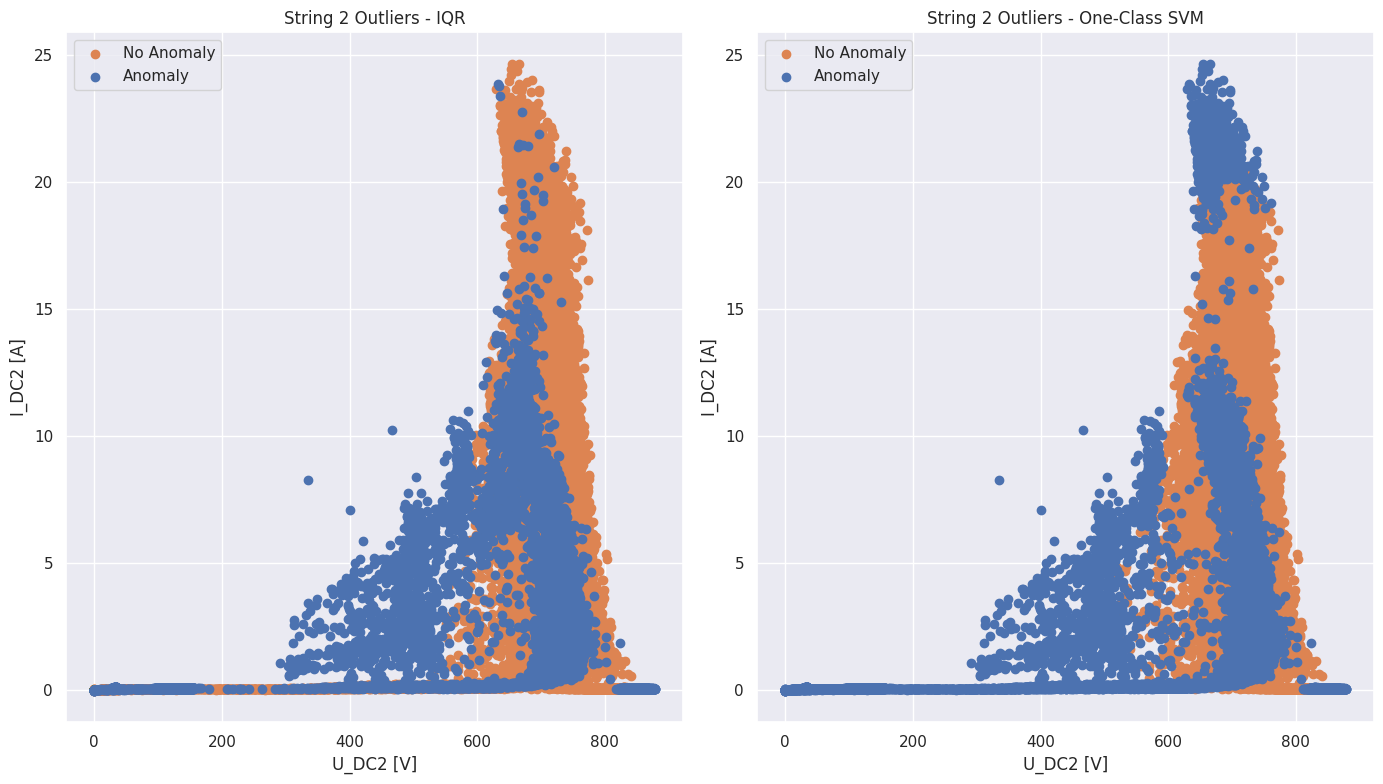

In [63]:
#STRING2

# Gráfico 1
plt.figure(figsize=(14, 8))

# Gráfico 1
plt.subplot(1,2,1)
plt.scatter(no_anomaly_iqr['U_DC2'], no_anomaly_iqr['I_DC2'], label='No Anomaly',color='#dd8452')
plt.scatter(anomaly_iqr['U_DC2'], anomaly_iqr['I_DC2'], label='Anomaly',color= '#4c72b0')
plt.xlabel('U_DC2 [V]')
plt.ylabel('I_DC2 [A]')
plt.legend()
plt.title('String 2 Outliers - IQR')

# Gráfico 2
plt.subplot(1,2,2)
plt.scatter(no_anomaly_ae['U_DC2'], no_anomaly_ae['I_DC2'], label='No Anomaly',color='#dd8452')
plt.scatter(anomaly_ae['U_DC2'], anomaly_ae['I_DC2'], label='Anomaly',color= '#4c72b0')
plt.xlabel('U_DC2 [V]')
plt.ylabel('I_DC2 [A]')
plt.legend()
plt.title('String 2 Outliers - One-Class SVM')


# Ajustes de diseño
plt.tight_layout()
plt.show()

In [64]:
#Inicializar etiquetas - No fault
ae_df['Label'] = 'No Fault'
ae_df['Anomaly_String1'] = 'No Fault'
ae_df['Anomaly_String2'] = 'No Fault'

In [65]:
ae_df

,Timestamp,U_DC1,U_DC2,I_DC1,I_DC2,Anomaly,Label,Anomaly_String1,Anomaly_String2
0,2019-08-02 16:25:00,777.010,768.710,2.700,2.607,0,No Fault,No Fault,No Fault
1,2019-08-02 16:30:00,761.130,745.964,3.862,3.748,0,No Fault,No Fault,No Fault
2,2019-08-02 16:35:00,736.754,742.908,3.228,3.192,0,No Fault,No Fault,No Fault
3,2019-08-02 16:40:00,731.928,732.224,2.568,2.484,0,No Fault,No Fault,No Fault
4,2019-08-02 16:45:00,723.546,720.698,1.654,1.640,0,No Fault,No Fault,No Fault
...,...,...,...,...,...,...,...,...,...
150393,2023-06-02 10:10:00,712.860,698.410,15.514,15.758,0,No Fault,No Fault,No Fault
150394,2023-06-02 10:15:00,703.810,696.148,16.136,16.278,0,No Fault,No Fault,No Fault
150395,2023-06-02 10:20:00,702.586,466.782,16.520,10.250,1,No Fault,No Fault,No Fault
150396,2023-06-02 10:25:00,703.080,32.316,15.754,0.080,1,No Fault,No Fault,No Fault


NEW PLOTS - AE_LSTM



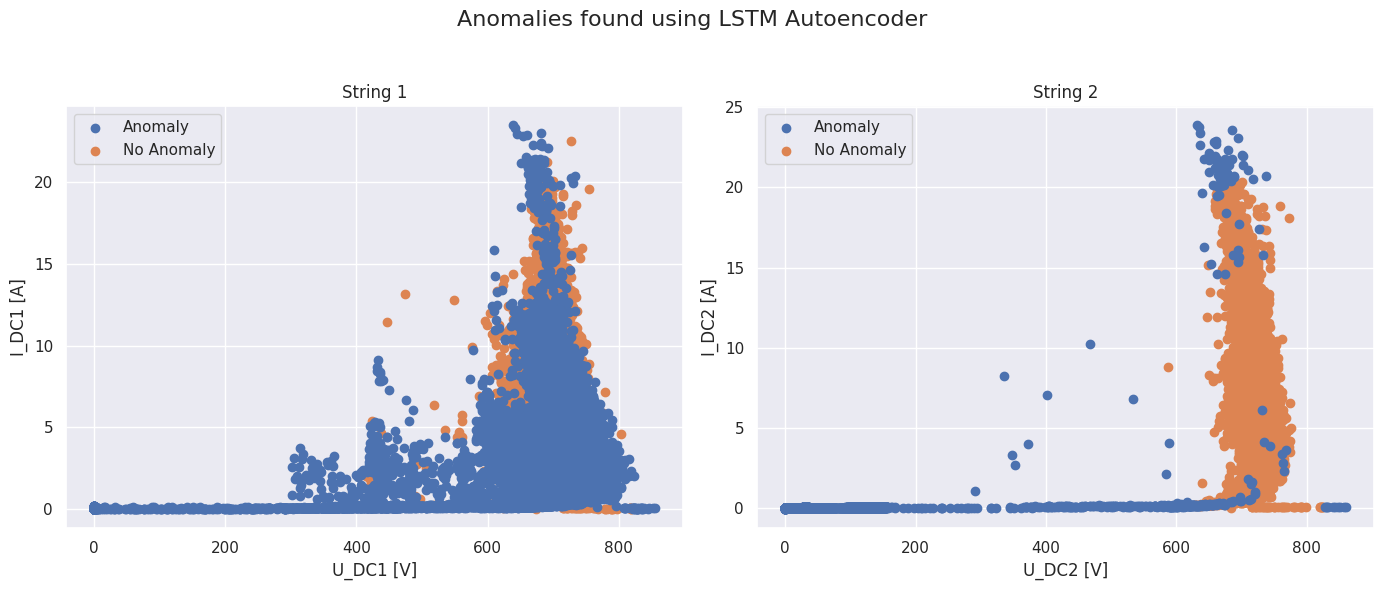

In [166]:
import matplotlib.pyplot as plt

# Create the figure with the 14x6 aspect ratio
plt.figure(figsize=(14, 6))

# Use suptitle for the overarching figure title
plt.suptitle("Anomalies found using LSTM Autoencoder", fontsize=16)

# --- Subplot 1: String 1 (Left) ---
plt.subplot(1, 2, 1)
# Plot Anomalies on top (zorder=2) in Blue (C0)
plt.scatter(anomaly_ae_test['U_DC1'], anomaly_ae_test['I_DC1'], label='Anomaly', color='C0', zorder=2)
# Plot Normal data on bottom (zorder=1) in Orange (C1)
plt.scatter(no_anomaly_ae_test['U_DC1'], no_anomaly_ae_test['I_DC1'], label='No Anomaly', color='C1', zorder=1)
plt.xlabel('U_DC1 [V]')
plt.ylabel('I_DC1 [A]')
plt.title('String 1')
plt.legend()

# --- Subplot 2: String 2 (Right) ---
plt.subplot(1, 2, 2)
# Plot Anomalies on top (zorder=2) in Blue (C0)
plt.scatter(anomaly_ae_test['U_DC2'], anomaly_ae_test['I_DC2'], label='Anomaly', color='C0', zorder=2)
# Plot Normal data on bottom (zorder=1) in Orange (C1)
plt.scatter(no_anomaly_ae_test['U_DC2'], no_anomaly_ae_test['I_DC2'], label='No Anomaly', color='C1', zorder=1)
plt.xlabel('U_DC2 [V]')
plt.ylabel('I_DC2 [A]')
plt.title('String 2')
plt.legend()

# Adjust layout to prevent overlapping and render to screen
plt.tight_layout(rect=[0, 0, 1, 0.95])
plt.show()

## **ENCONTRAR VMP y IMP**

In [66]:
ae_df['P_DC1'] = ae_df['U_DC1']*ae_df['I_DC1']
ae_df['P_DC2'] = ae_df['U_DC2']*ae_df['I_DC2']

In [67]:
ae_df['P_DC1'].idxmax()

9019

In [68]:
ae_df['P_DC2'].idxmax()

9033

In [69]:
v_mp1 = ae_df['U_DC1'].iloc[9019]
i_mp1 = ae_df['I_DC1'].iloc[9019]

In [70]:
v_mp1,i_mp1

(np.float64(716.312), np.float64(23.022))

In [71]:
v_mp2 = ae_df['U_DC2'].iloc[9033]
i_mp2 = ae_df['I_DC2'].iloc[9033]

In [72]:
v_mp2,i_mp2

(np.float64(685.026), np.float64(24.02))

/tmp/ipykernel_4208/3083877124.py:7: OptimizeWarning: Covariance of the parameters could not be estimated
  coef,_ = curve_fit(fun, x, y)


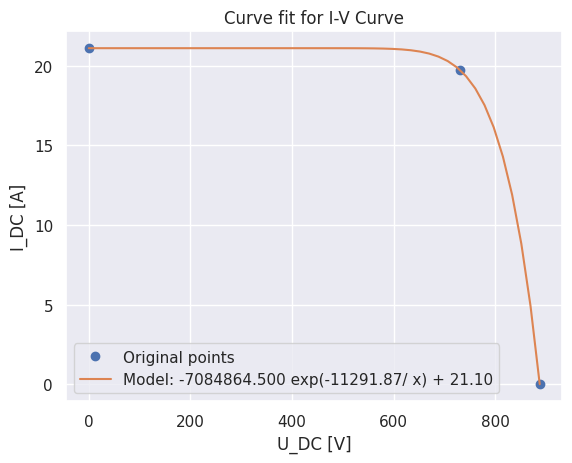

In [73]:
x = np.array([ 0.01,730.8,887.4])
y = np.array([21.1,19.72,0.01])

def fun(x, a, b, c):
    return a*np.exp(b/x)+c

coef,_ = curve_fit(fun, x, y)

plt.plot(x, y, 'o', label='Original points')
plt.xlabel('U_DC [V]')
plt.ylabel('I_DC [A]')
plt.title('Curve fit for I-V Curve')
plt.plot(np.linspace(x[0],x[-1]), fun(np.linspace(x[0],x[-1]), *coef), label=f'Model: %5.3f exp(%4.2f/ x) + %4.2f' % tuple(coef) )
plt.legend()
plt.show()

## STRING 1

/tmp/ipykernel_4208/703433318.py:5: UserWarning: color is redundantly defined by the 'color' keyword argument and the fmt string "r" (-> color=(0.7686274509803922, 0.3058823529411765, 0.3215686274509804, 1)). The keyword argument will take precedence.
  plt.plot(x, y, 'r', color='black')


Text(0.1, 0.85, '1000 W/m^2')

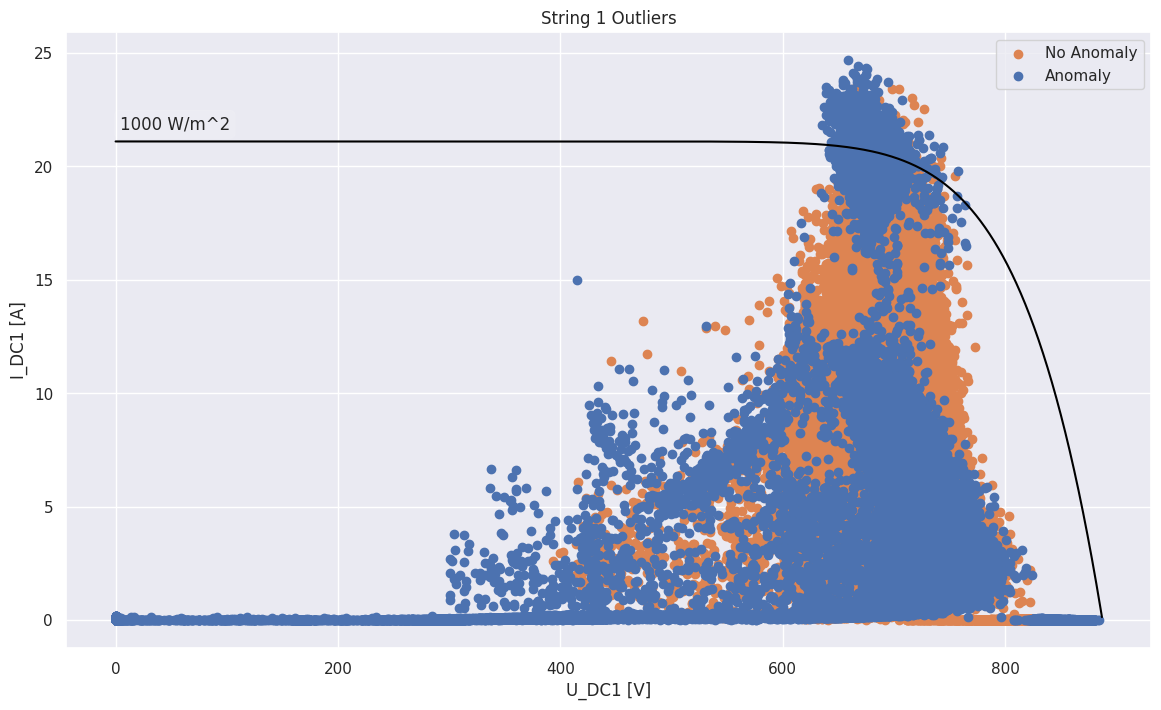

In [74]:
plt.figure(figsize=(14, 8))
x = np.arange(0.01,887.4,1)
y = -7084864.500*np.exp(-11291.87/x)+21.10

plt.plot(x, y, 'r', color='black')
plt.scatter(no_anomaly_ae['U_DC1'], no_anomaly_ae['I_DC1'], label='No Anomaly',color='#dd8452')
plt.scatter(anomaly_ae['U_DC1'], anomaly_ae['I_DC1'], label='Anomaly',color= '#4c72b0')
plt.xlabel('U_DC1 [V]')
plt.ylabel('I_DC1 [A]')
plt.legend()
plt.title('String 1 Outliers')

plt.annotate('1000 W/m^2', xy=(0.1, 0.85), xycoords='axes fraction',
             fontsize=12, ha='center', va='center',
             bbox=dict(boxstyle='round', alpha=0.1, facecolor='white'))

In [75]:
ae_df['P_DC1'].mean()

np.float64(2918.4726760968833)

In [76]:
ae_df[(ae_df['P_DC1'] >= 2915) & (ae_df['P_DC1'] <= 2920) & (ae_df['I_DC1'] > 6)]

,Timestamp,U_DC1,U_DC2,I_DC1,I_DC2,Anomaly,Label,Anomaly_String1,Anomaly_String2,P_DC1,P_DC2
3519,2019-08-27 16:20:00,476.516,744.416,6.126,1.646,0,No Fault,No Fault,No Fault,2919.137016,1225.308736


In [77]:
ae_df[(ae_df['P_DC1'] >= 2915) & (ae_df['P_DC1'] <= 2920) & (ae_df['U_DC1'] > 400) & (ae_df['U_DC1'] < 500)]

,Timestamp,U_DC1,U_DC2,I_DC1,I_DC2,Anomaly,Label,Anomaly_String1,Anomaly_String2,P_DC1,P_DC2
3519,2019-08-27 16:20:00,476.516,744.416,6.126,1.646,0,No Fault,No Fault,No Fault,2919.137016,1225.308736


In [78]:
ae_df['I_DC1'].mean()

np.float64(4.134151039242543)

In [79]:
ae_df['U_DC1'].mean()

np.float64(693.9819170002261)

### SOMBREO

/tmp/ipykernel_4208/3645096734.py:5: UserWarning: color is redundantly defined by the 'color' keyword argument and the fmt string "r" (-> color=(0.7686274509803922, 0.3058823529411765, 0.3215686274509804, 1)). The keyword argument will take precedence.
  plt.plot(x, y, 'r', color='black')
/tmp/ipykernel_4208/3645096734.py:36: UserWarning: color is redundantly defined by the 'color' keyword argument and the fmt string "r" (-> color=(0.7686274509803922, 0.3058823529411765, 0.3215686274509804, 1)). The keyword argument will take precedence.
  plt.plot(x_mean_power1_yaxis, y_mean_power1_yaxis, 'r', color='purple')
/tmp/ipykernel_4208/3645096734.py:37: UserWarning: color is redundantly defined by the 'color' keyword argument and the fmt string "r" (-> color=(0.7686274509803922, 0.3058823529411765, 0.3215686274509804, 1)). The keyword argument will take precedence.
  plt.plot(x_mean_power1_xaxis, y_mean_power1_xaxis, 'r', color='purple')
/tmp/ipykernel_4208/3645096734.py:38: UserWarning: col

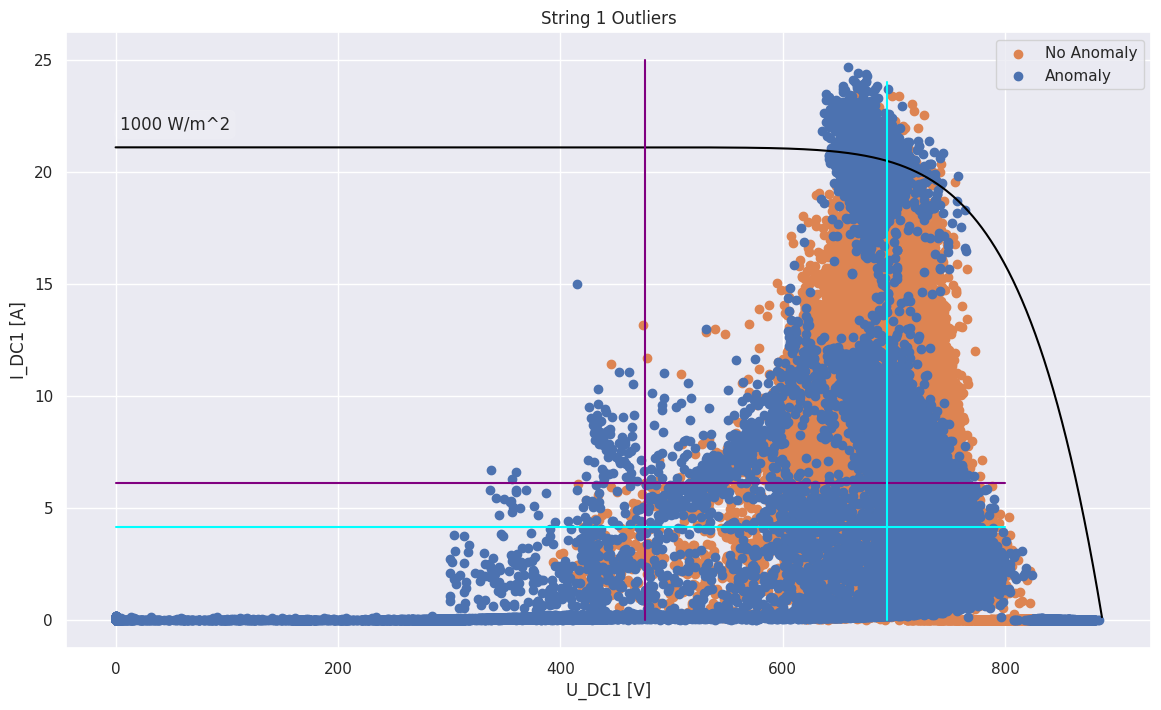

In [80]:
plt.figure(figsize=(14, 8))
x = np.arange(0.01,887.4,1)
y = -7084864.500*np.exp(-11291.87/x)+21.10

plt.plot(x, y, 'r', color='black')
plt.scatter(no_anomaly_ae['U_DC1'], no_anomaly_ae['I_DC1'], label='No Anomaly',color='#dd8452')
plt.scatter(anomaly_ae['U_DC1'], anomaly_ae['I_DC1'], label='Anomaly',color= '#4c72b0')
plt.xlabel('U_DC1 [V]')
plt.ylabel('I_DC1 [A]')
plt.legend()
plt.title('String 1 Outliers')

plt.annotate('1000 W/m^2', xy=(0.1, 0.85), xycoords='axes fraction',
             fontsize=12, ha='center', va='center',
             bbox=dict(boxstyle='round', alpha=0.1, facecolor='white'))

x_mean_power1 = 476.516
y_mean_power1 = 6.126

y_mean_power1_yaxis = np.arange(0,26,1)
x_mean_power1_yaxis = x_mean_power1*np.ones(y_mean_power1_yaxis.shape[0])

x_mean_power1_xaxis = np.arange(0,900,100)
y_mean_power1_xaxis = y_mean_power1*np.ones(x_mean_power1_xaxis.shape[0])

x_mean_voltage1 = 693.9819170002261
y_mean_current1 = 4.134151039242543

y_mean_voltage1_axis = np.arange(0,25,1)
x_mean_voltage1_axis = x_mean_voltage1*np.ones(y_mean_voltage1_axis.shape[0])

x_mean_current1_axis = np.arange(0,900,100)
y_mean_current1_axis = y_mean_current1*np.ones(x_mean_current1_axis.shape[0])


plt.plot(x_mean_power1_yaxis, y_mean_power1_yaxis, 'r', color='purple')
plt.plot(x_mean_power1_xaxis, y_mean_power1_xaxis, 'r', color='purple')
plt.plot(x_mean_voltage1_axis, y_mean_voltage1_axis, 'r', color='cyan')
plt.plot(x_mean_current1_axis, y_mean_current1_axis, 'r', color='cyan')

Los datos de sombreo son entonces, aquellos que están en el cuadrante inferior izquierdo y son superiores a 0

In [81]:
shading_power1 = ae_df[(ae_df['Anomaly'] == 1) & (ae_df['I_DC1']>0) & (ae_df['U_DC1']>0) & (ae_df['U_DC1']< x_mean_power1) & (ae_df['I_DC1']< y_mean_power1)]
shading_voltage1 = ae_df[(ae_df['Anomaly'] == 1) & (ae_df['I_DC1']>0) & (ae_df['U_DC1']>0) & (ae_df['U_DC1']< x_mean_voltage1) & (ae_df['I_DC1']< 19.1)]
shading_current1 = ae_df[(ae_df['Anomaly'] == 1) &(ae_df['I_DC1']>0) & (ae_df['U_DC1']>0) & (ae_df['I_DC1']< y_mean_current1) ]

In [82]:
shading_union = shading_power1.index.union(shading_voltage1.index).union(shading_current1.index)

In [83]:
ae_df.loc[shading_union,'Anomaly_String1'] = 'Shading'

In [84]:
ae_df[ae_df['Anomaly_String1'] == 'Shading']

,Timestamp,U_DC1,U_DC2,I_DC1,I_DC2,Anomaly,Label,Anomaly_String1,Anomaly_String2,P_DC1,P_DC2
15,2019-08-03 05:50:00,377.060,366.518,0.032,0.056,1,No Fault,Shading,No Fault,12.065920,20.525008
16,2019-08-03 05:55:00,392.552,511.468,0.056,0.084,1,No Fault,Shading,No Fault,21.982912,42.963312
17,2019-08-03 06:00:00,466.012,595.256,0.090,0.122,1,No Fault,Shading,No Fault,41.941080,72.621232
18,2019-08-03 06:05:00,463.102,639.724,0.166,0.192,1,No Fault,Shading,No Fault,76.874932,122.827008
19,2019-08-03 06:10:00,503.256,666.558,0.256,0.280,1,No Fault,Shading,No Fault,128.833536,186.636240
...,...,...,...,...,...,...,...,...,...,...,...
150339,2023-06-02 05:40:00,94.104,94.308,0.004,0.010,1,No Fault,Shading,No Fault,0.376416,0.943080
150340,2023-06-02 05:45:00,388.618,418.116,0.038,0.062,1,No Fault,Shading,No Fault,14.767484,25.923192
150341,2023-06-02 05:50:00,381.454,486.948,0.100,0.122,1,No Fault,Shading,No Fault,38.145400,59.407656
150342,2023-06-02 05:55:00,513.446,623.132,0.186,0.202,1,No Fault,Shading,No Fault,95.500956,125.872664


### CORTO CIRCUITO

/tmp/ipykernel_4208/3233553893.py:5: UserWarning: color is redundantly defined by the 'color' keyword argument and the fmt string "r" (-> color=(0.7686274509803922, 0.3058823529411765, 0.3215686274509804, 1)). The keyword argument will take precedence.
  plt.plot(x, y, 'r', color='black')
/tmp/ipykernel_4208/3233553893.py:27: UserWarning: color is redundantly defined by the 'color' keyword argument and the fmt string "r" (-> color=(0.7686274509803922, 0.3058823529411765, 0.3215686274509804, 1)). The keyword argument will take precedence.
  plt.plot(upper_idc_xaxis, upper_idc_yaxis, 'r', color='purple')
/tmp/ipykernel_4208/3233553893.py:28: UserWarning: color is redundantly defined by the 'color' keyword argument and the fmt string "r" (-> color=(0.7686274509803922, 0.3058823529411765, 0.3215686274509804, 1)). The keyword argument will take precedence.
  plt.plot(lower_idc_xaxis, lower_idc_yaxis, 'r', color='purple')


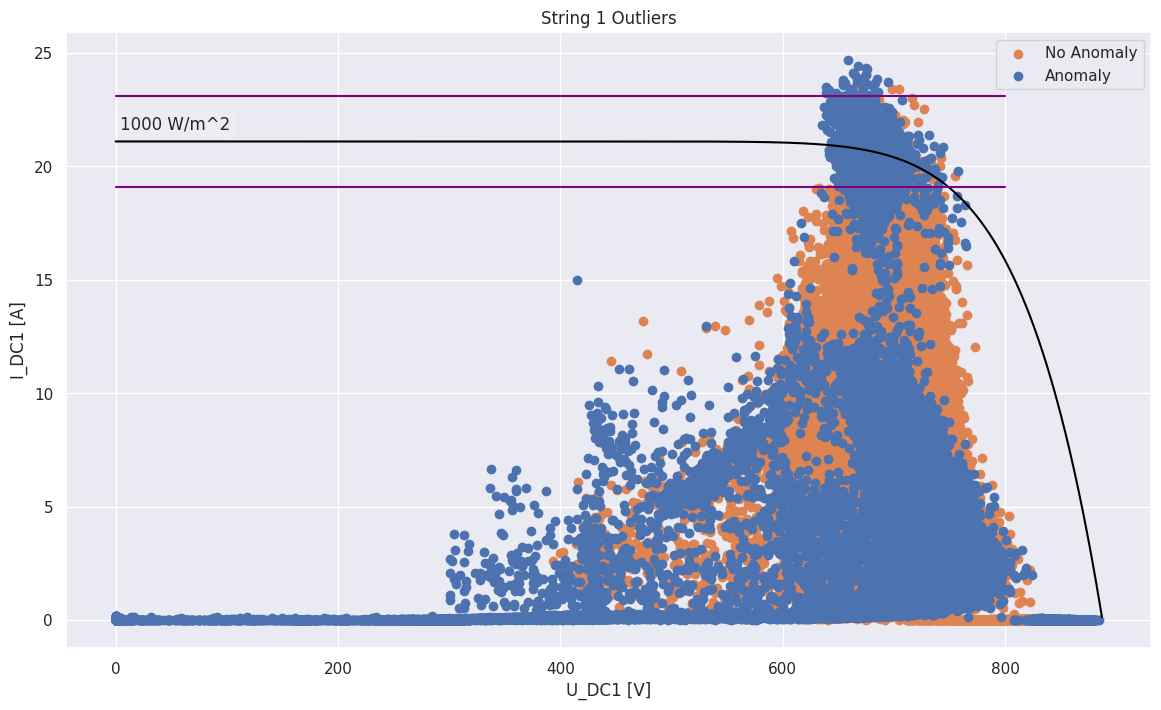

In [85]:
plt.figure(figsize=(14, 8))
x = np.arange(0.01,887.4,1)
y = -7084864.500*np.exp(-11291.87/x)+21.10

plt.plot(x, y, 'r', color='black')
plt.scatter(no_anomaly_ae['U_DC1'], no_anomaly_ae['I_DC1'], label='No Anomaly',color='#dd8452')
plt.scatter(anomaly_ae['U_DC1'], anomaly_ae['I_DC1'], label='Anomaly',color= '#4c72b0')
plt.xlabel('U_DC1 [V]')
plt.ylabel('I_DC1 [A]')
plt.legend()
plt.title('String 1 Outliers')

plt.annotate('1000 W/m^2', xy=(0.1, 0.85), xycoords='axes fraction',
             fontsize=12, ha='center', va='center',
             bbox=dict(boxstyle='round', alpha=0.1, facecolor='white'))

upper_limit_idc = 21.1 + 2
lower_limit_idc = 21.1 - 2

upper_idc_xaxis =  np.arange(0,900,100)
upper_idc_yaxis = upper_limit_idc*np.ones(upper_idc_xaxis.shape[0])

lower_idc_xaxis =  np.arange(0,900,100)
lower_idc_yaxis = lower_limit_idc*np.ones(lower_idc_xaxis.shape[0])


plt.plot(upper_idc_xaxis, upper_idc_yaxis, 'r', color='purple')
plt.plot(lower_idc_xaxis, lower_idc_yaxis, 'r', color='purple')

In [86]:
sc_fault1 = ae_df[(ae_df['Anomaly'] == 1) & (ae_df['I_DC1']>=lower_limit_idc) & (ae_df['I_DC1']<=upper_limit_idc)]

In [87]:
index_sc1 = sc_fault1.index

In [88]:
ae_df.loc[index_sc1,'Anomaly_String1'] = 'Short Circuit'

In [89]:
ae_df[ae_df['Anomaly_String1'] == 'Short Circuit']

,Timestamp,U_DC1,U_DC2,I_DC1,I_DC2,Anomaly,Label,Anomaly_String1,Anomaly_String2,P_DC1,P_DC2
639,2019-08-07 11:15:00,680.792,687.284,20.836,20.948,1,No Fault,Short Circuit,No Fault,14184.982112,14397.225232
641,2019-08-07 11:25:00,693.494,689.792,19.912,20.514,1,No Fault,Short Circuit,No Fault,13808.852528,14150.393088
669,2019-08-07 13:45:00,701.630,696.212,20.178,21.078,1,No Fault,Short Circuit,No Fault,14157.490140,14674.756536
794,2019-08-08 12:25:00,683.550,685.944,20.950,20.928,1,No Fault,Short Circuit,No Fault,14320.372500,14355.436032
795,2019-08-08 12:30:00,679.078,676.326,20.824,20.830,1,No Fault,Short Circuit,No Fault,14141.120272,14087.870580
...,...,...,...,...,...,...,...,...,...,...,...
149136,2023-05-24 12:15:00,682.942,681.218,21.268,21.378,1,No Fault,Short Circuit,No Fault,14524.810456,14563.078404
149137,2023-05-24 12:20:00,669.718,659.056,22.264,21.968,1,No Fault,Short Circuit,No Fault,14910.601552,14478.142208
149844,2023-05-29 11:55:00,690.190,687.906,20.644,20.632,1,No Fault,Short Circuit,No Fault,14248.282360,14192.876592
150119,2023-05-31 11:05:00,690.784,682.082,19.938,20.456,1,No Fault,Short Circuit,No Fault,13772.851392,13952.669392


### CIRCUITO ABIERTO

Todas aquellas fallas cuya corriente sea igual a 0

/tmp/ipykernel_4208/4234527810.py:5: UserWarning: color is redundantly defined by the 'color' keyword argument and the fmt string "r" (-> color=(0.7686274509803922, 0.3058823529411765, 0.3215686274509804, 1)). The keyword argument will take precedence.
  plt.plot(x, y, 'r', color='black')
/tmp/ipykernel_4208/4234527810.py:21: UserWarning: color is redundantly defined by the 'color' keyword argument and the fmt string "r" (-> color=(0.7686274509803922, 0.3058823529411765, 0.3215686274509804, 1)). The keyword argument will take precedence.
  plt.plot(voltage_zeros, current, 'r', color='purple')


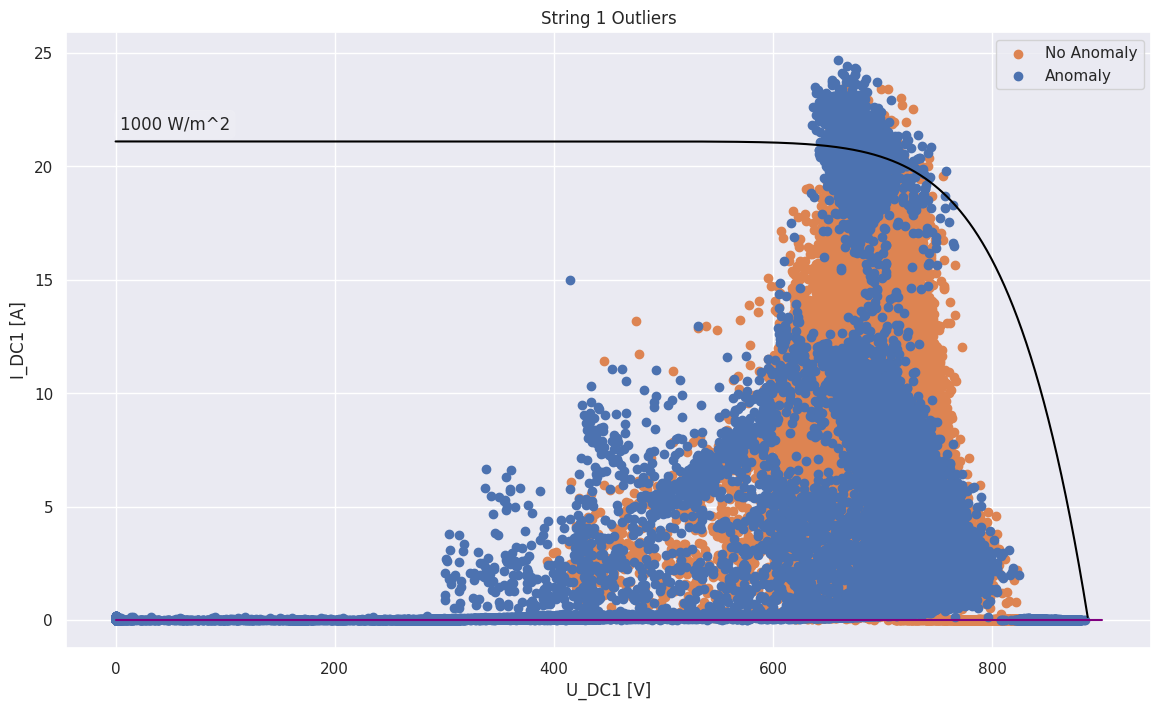

In [90]:
plt.figure(figsize=(14, 8))
x = np.arange(0.01,887.4,1)
y = -7084864.500*np.exp(-11291.87/x)+21.10

plt.plot(x, y, 'r', color='black')
plt.scatter(no_anomaly_ae['U_DC1'], no_anomaly_ae['I_DC1'], label='No Anomaly',color='#dd8452')
plt.scatter(anomaly_ae['U_DC1'], anomaly_ae['I_DC1'], label='Anomaly',color= '#4c72b0')
plt.xlabel('U_DC1 [V]')
plt.ylabel('I_DC1 [A]')
plt.legend()
plt.title('String 1 Outliers')

plt.annotate('1000 W/m^2', xy=(0.1, 0.85), xycoords='axes fraction',
             fontsize=12, ha='center', va='center',
             bbox=dict(boxstyle='round', alpha=0.1, facecolor='white'))

current = np.zeros(10)
voltage_zeros = np.arange(0,1000,100)


plt.plot(voltage_zeros, current, 'r', color='purple')

In [91]:
oc_fault1 = ae_df[(ae_df['Anomaly'] == 1) & (ae_df['I_DC1']==0) & (ae_df['U_DC1']!=0) ]

In [92]:
oc_fault1.shape

(1040, 11)

In [93]:
index_oc1 = oc_fault1.index

In [94]:
ae_df.loc[index_oc1,'Anomaly_String1'] = 'Open Circuit'

In [95]:
ae_df[(ae_df['Anomaly_String1'] == 'Open Circuit')]

,Timestamp,U_DC1,U_DC2,I_DC1,I_DC2,Anomaly,Label,Anomaly_String1,Anomaly_String2,P_DC1,P_DC2
5940,2019-09-14 15:30:00,833.476,835.932,0.0,0.060,1,No Fault,Open Circuit,No Fault,0.0,50.155920
5957,2019-09-14 16:55:00,824.730,826.150,0.0,0.060,1,No Fault,Open Circuit,No Fault,0.0,49.569000
5958,2019-09-14 17:00:00,822.650,824.114,0.0,0.060,1,No Fault,Open Circuit,No Fault,0.0,49.446840
15137,2019-11-18 06:35:00,843.602,849.354,0.0,0.050,1,No Fault,Open Circuit,No Fault,0.0,42.467700
15138,2019-11-18 06:40:00,858.404,860.010,0.0,0.050,1,No Fault,Open Circuit,No Fault,0.0,43.000500
...,...,...,...,...,...,...,...,...,...,...,...
101238,2021-07-23 15:45:00,829.162,829.728,0.0,0.048,1,No Fault,Open Circuit,No Fault,0.0,39.826944
101245,2021-07-23 16:20:00,834.780,834.910,0.0,0.050,1,No Fault,Open Circuit,No Fault,0.0,41.745500
101246,2021-07-23 16:25:00,837.212,837.172,0.0,0.040,1,No Fault,Open Circuit,No Fault,0.0,33.486880
101729,2021-07-27 10:15:00,825.996,828.188,0.0,0.060,1,No Fault,Open Circuit,No Fault,0.0,49.691280


### FALLA NO IDENTIFICADA

/tmp/ipykernel_4208/3565300763.py:5: UserWarning: color is redundantly defined by the 'color' keyword argument and the fmt string "r" (-> color=(0.7686274509803922, 0.3058823529411765, 0.3215686274509804, 1)). The keyword argument will take precedence.
  plt.plot(x, y, 'r', color='black')
/tmp/ipykernel_4208/3565300763.py:27: UserWarning: color is redundantly defined by the 'color' keyword argument and the fmt string "r" (-> color=(0.7686274509803922, 0.3058823529411765, 0.3215686274509804, 1)). The keyword argument will take precedence.
  plt.plot(upper_idc_xaxis, upper_idc_yaxis, 'r', color='purple')


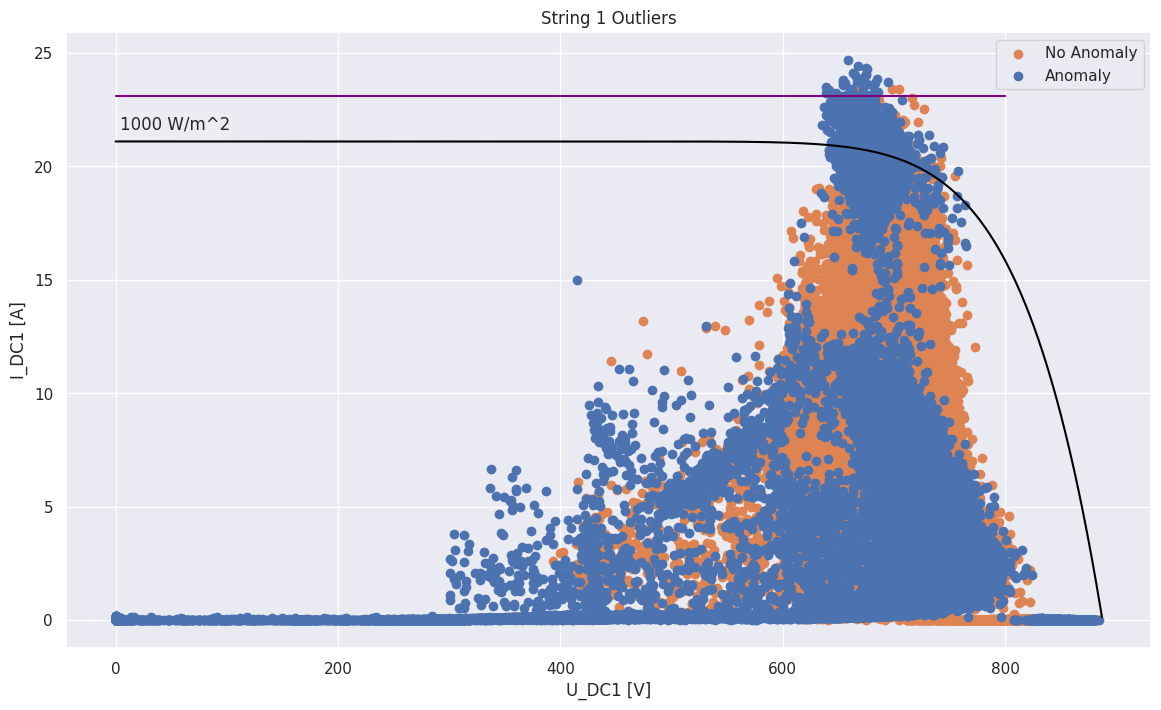

In [96]:
plt.figure(figsize=(14, 8))
x = np.arange(0.01,887.4,1)
y = -7084864.500*np.exp(-11291.87/x)+21.10

plt.plot(x, y, 'r', color='black')
plt.scatter(no_anomaly_ae['U_DC1'], no_anomaly_ae['I_DC1'], label='No Anomaly',color='#dd8452')
plt.scatter(anomaly_ae['U_DC1'], anomaly_ae['I_DC1'], label='Anomaly',color= '#4c72b0')
plt.xlabel('U_DC1 [V]')
plt.ylabel('I_DC1 [A]')
plt.legend()
plt.title('String 1 Outliers')

plt.annotate('1000 W/m^2', xy=(0.1, 0.85), xycoords='axes fraction',
             fontsize=12, ha='center', va='center',
             bbox=dict(boxstyle='round', alpha=0.1, facecolor='white'))

upper_limit_idc = 21.1 + 2
lower_limit_idc = 21.1 - 2

upper_idc_xaxis =  np.arange(0,900,100)
upper_idc_yaxis = upper_limit_idc*np.ones(upper_idc_xaxis.shape[0])

lower_idc_xaxis =  np.arange(0,900,100)
lower_idc_yaxis = lower_limit_idc*np.ones(lower_idc_xaxis.shape[0])


plt.plot(upper_idc_xaxis, upper_idc_yaxis, 'r', color='purple')

In [97]:
unknown_1 = ae_df[(ae_df['Anomaly'] == 1) & (ae_df['I_DC1']>=upper_limit_idc)]

In [98]:
index_u1 = unknown_1.index

In [99]:
ae_df.loc[index_u1,'Anomaly_String1'] = 'Unknown'

In [100]:
ae_df[(ae_df['Anomaly_String1'] == 'Unknown')]

,Timestamp,U_DC1,U_DC2,I_DC1,I_DC2,Anomaly,Label,Anomaly_String1,Anomaly_String2,P_DC1,P_DC2
6890,2019-09-21 11:40:00,672.568,709.216,23.908,20.434,1,No Fault,Unknown,No Fault,16079.755744,14492.119744
8748,2019-10-04 11:55:00,681.868,724.454,23.206,20.618,1,No Fault,Unknown,No Fault,15823.428808,14936.792572
9021,2019-10-06 10:50:00,675.496,720.944,24.274,19.798,1,No Fault,Unknown,No Fault,16396.989904,14273.249312
9028,2019-10-06 11:25:00,674.840,722.888,24.354,19.904,1,No Fault,Unknown,No Fault,16435.053360,14388.362752
11769,2019-10-25 12:35:00,660.612,669.572,23.192,22.520,1,No Fault,Unknown,No Fault,15320.913504,15078.761440
12747,2019-11-01 10:20:00,658.870,710.360,23.202,20.572,1,No Fault,Unknown,No Fault,15287.101740,14613.525920
12752,2019-11-01 10:45:00,669.722,724.146,23.796,19.986,1,No Fault,Unknown,No Fault,15936.704712,14472.781956
12753,2019-11-01 10:50:00,662.710,714.036,24.110,20.548,1,No Fault,Unknown,No Fault,15977.938100,14672.011728
14047,2019-11-10 11:10:00,678.420,704.604,23.150,21.322,1,No Fault,Unknown,No Fault,15705.423000,15023.566488
14210,2019-11-11 12:55:00,674.468,722.842,24.072,20.100,1,No Fault,Unknown,No Fault,16235.793696,14529.124200


## STRING 2

/tmp/ipykernel_4208/391859076.py:5: UserWarning: color is redundantly defined by the 'color' keyword argument and the fmt string "r" (-> color=(0.7686274509803922, 0.3058823529411765, 0.3215686274509804, 1)). The keyword argument will take precedence.
  plt.plot(x, y, 'r', color='black')


Text(0.1, 0.85, '1000 W/m^2')

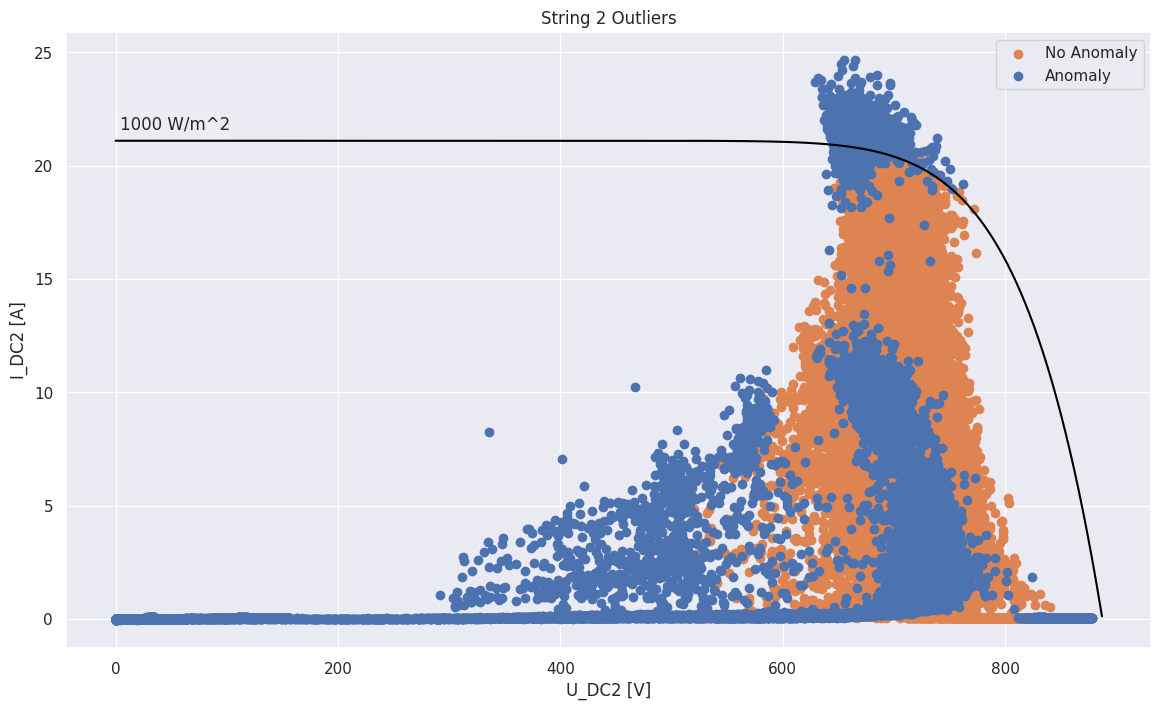

In [101]:
plt.figure(figsize=(14, 8))
x = np.arange(0.01,887.4,1)
y = -7084864.500*np.exp(-11291.87/x)+21.10

plt.plot(x, y, 'r', color='black')
plt.scatter(no_anomaly_ae['U_DC2'], no_anomaly_ae['I_DC2'], label='No Anomaly',color='#dd8452')
plt.scatter(anomaly_ae['U_DC2'], anomaly_ae['I_DC2'], label='Anomaly',color= '#4c72b0')
plt.xlabel('U_DC2 [V]')
plt.ylabel('I_DC2 [A]')
plt.legend()
plt.title('String 2 Outliers')

plt.annotate('1000 W/m^2', xy=(0.1, 0.85), xycoords='axes fraction',
             fontsize=12, ha='center', va='center',
             bbox=dict(boxstyle='round', alpha=0.1, facecolor='white'))

In [102]:
ae_df['P_DC2'].mean()

np.float64(2091.00719470713)

In [103]:
ae_df[(ae_df['P_DC2'] >= 2000) & (ae_df['P_DC2'] <= 2100) & (ae_df['I_DC2'] >= 4.5)]

,Timestamp,U_DC1,U_DC2,I_DC1,I_DC2,Anomaly,Label,Anomaly_String1,Anomaly_String2,P_DC1,P_DC2
5661,2019-09-12 16:00:00,725.734,454.512,5.222,4.508,1,No Fault,No Fault,No Fault,3789.782948,2048.940096
21607,2020-01-02 16:55:00,731.206,408.542,3.580,4.972,1,No Fault,Shading,No Fault,2617.717480,2031.270824
22445,2020-01-08 16:50:00,474.460,445.506,3.944,4.574,1,No Fault,Shading,No Fault,1871.270240,2037.744444
25625,2020-01-31 17:05:00,711.352,428.612,3.298,4.764,1,No Fault,Shading,No Fault,2346.038896,2041.907568


In [104]:
2091.0071947071306 - 2048.940096

42.067098707130754

In [105]:
2091.0071947071306 - 2121.659808

-30.65261329286932

In [106]:
ae_df[(ae_df['P_DC2'] >= 2100) & (ae_df['P_DC2'] <= 2150) & (ae_df['I_DC2'] >= 4.5)]

,Timestamp,U_DC1,U_DC2,I_DC1,I_DC2,Anomaly,Label,Anomaly_String1,Anomaly_String2,P_DC1,P_DC2
17098,2019-12-01 16:30:00,707.556,453.718,2.912,4.722,1,No Fault,Shading,No Fault,2060.403072,2142.456396
21606,2020-01-02 16:50:00,692.314,416.782,3.946,5.140,1,No Fault,Shading,No Fault,2731.871044,2142.259480
22723,2020-01-10 16:50:00,690.474,454.018,2.960,4.676,1,No Fault,Shading,No Fault,2043.803040,2122.988168
27276,2020-02-12 17:00:00,700.986,458.044,2.692,4.632,1,No Fault,Shading,No Fault,1887.054312,2121.659808


In [107]:
ae_df['I_DC2'].mean()

np.float64(2.9501705940238567)

In [108]:
ae_df['U_DC2'].mean()

np.float64(554.7488825117355)

### SOMBREO

/tmp/ipykernel_4208/3065282788.py:5: UserWarning: color is redundantly defined by the 'color' keyword argument and the fmt string "r" (-> color=(0.7686274509803922, 0.3058823529411765, 0.3215686274509804, 1)). The keyword argument will take precedence.
  plt.plot(x, y, 'r', color='black')
/tmp/ipykernel_4208/3065282788.py:35: UserWarning: color is redundantly defined by the 'color' keyword argument and the fmt string "r" (-> color=(0.7686274509803922, 0.3058823529411765, 0.3215686274509804, 1)). The keyword argument will take precedence.
  plt.plot(x_mean_power1_yaxis, y_mean_power1_yaxis, 'r', color='purple')
/tmp/ipykernel_4208/3065282788.py:36: UserWarning: color is redundantly defined by the 'color' keyword argument and the fmt string "r" (-> color=(0.7686274509803922, 0.3058823529411765, 0.3215686274509804, 1)). The keyword argument will take precedence.
  plt.plot(x_mean_power1_xaxis, y_mean_power1_xaxis, 'r', color='purple')
/tmp/ipykernel_4208/3065282788.py:37: UserWarning: col

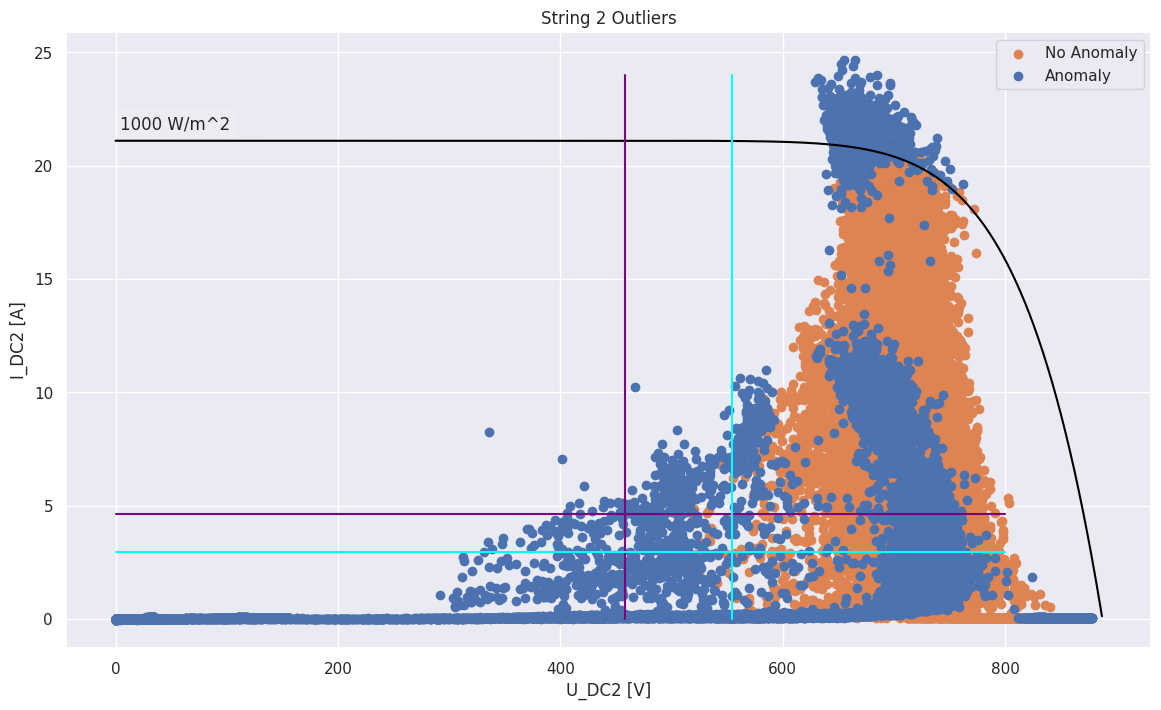

In [109]:
plt.figure(figsize=(14, 8))
x = np.arange(0.01,887.4,1)
y = -7084864.500*np.exp(-11291.87/x)+21.10

plt.plot(x, y, 'r', color='black')
plt.scatter(no_anomaly_ae['U_DC2'], no_anomaly_ae['I_DC2'], label='No Anomaly',color='#dd8452')
plt.scatter(anomaly_ae['U_DC2'], anomaly_ae['I_DC2'], label='Anomaly',color= '#4c72b0')
plt.xlabel('U_DC2 [V]')
plt.ylabel('I_DC2 [A]')
plt.legend()
plt.title('String 2 Outliers')

plt.annotate('1000 W/m^2', xy=(0.1, 0.85), xycoords='axes fraction',
             fontsize=12, ha='center', va='center',
             bbox=dict(boxstyle='round', alpha=0.1, facecolor='white'))

x_mean_power1 = 458.044
y_mean_power1 = 4.632

y_mean_power1_yaxis = np.arange(0,25,1)
x_mean_power1_yaxis = x_mean_power1*np.ones(y_mean_power1_yaxis.shape[0])

x_mean_power1_xaxis = np.arange(0,900,100)
y_mean_power1_xaxis = y_mean_power1*np.ones(x_mean_power1_xaxis.shape[0])

x_mean_voltage1 = 554.7488825117355
y_mean_current1 = 2.9501705940238563

y_mean_voltage1_axis = np.arange(0,25,1)
x_mean_voltage1_axis = x_mean_voltage1*np.ones(y_mean_voltage1_axis.shape[0])

x_mean_current1_axis = np.arange(0,900,100)
y_mean_current1_axis = y_mean_current1*np.ones(x_mean_current1_axis.shape[0])

plt.plot(x_mean_power1_yaxis, y_mean_power1_yaxis, 'r', color='purple')
plt.plot(x_mean_power1_xaxis, y_mean_power1_xaxis, 'r', color='purple')
plt.plot(x_mean_voltage1_axis, y_mean_voltage1_axis, 'r', color='cyan')
plt.plot(x_mean_current1_axis, y_mean_current1_axis, 'r', color='cyan')

In [110]:
shading_power2 = ae_df[(ae_df['Anomaly'] == 1) & (ae_df['I_DC2']> 0) & (ae_df['U_DC2']> 0) & (ae_df['U_DC2']< x_mean_power1) & (ae_df['I_DC2']< y_mean_power1)]
shading_voltage2 = ae_df[(ae_df['Anomaly'] == 1) & (ae_df['I_DC2']>0) & (ae_df['U_DC1']>0) & (ae_df['U_DC2']< x_mean_voltage1) & (ae_df['I_DC2']< 19.1)]
shading_current2 = ae_df[(ae_df['Anomaly'] == 1) &(ae_df['I_DC2']>0) & (ae_df['U_DC2']>0) & (ae_df['I_DC2']< y_mean_current1) ]

In [111]:
shading_union = shading_power2.index.union(shading_voltage2.index).union(shading_current2.index)

In [112]:
ae_df.loc[shading_union,'Anomaly_String2'] = 'Shading'

In [113]:
ae_df[ae_df['Anomaly_String2'] == 'Shading']

,Timestamp,U_DC1,U_DC2,I_DC1,I_DC2,Anomaly,Label,Anomaly_String1,Anomaly_String2,P_DC1,P_DC2
15,2019-08-03 05:50:00,377.060,366.518,0.032,0.056,1,No Fault,Shading,Shading,12.065920,20.525008
16,2019-08-03 05:55:00,392.552,511.468,0.056,0.084,1,No Fault,Shading,Shading,21.982912,42.963312
17,2019-08-03 06:00:00,466.012,595.256,0.090,0.122,1,No Fault,Shading,Shading,41.941080,72.621232
18,2019-08-03 06:05:00,463.102,639.724,0.166,0.192,1,No Fault,Shading,Shading,76.874932,122.827008
19,2019-08-03 06:10:00,503.256,666.558,0.256,0.280,1,No Fault,Shading,Shading,128.833536,186.636240
...,...,...,...,...,...,...,...,...,...,...,...
150341,2023-06-02 05:50:00,381.454,486.948,0.100,0.122,1,No Fault,Shading,Shading,38.145400,59.407656
150342,2023-06-02 05:55:00,513.446,623.132,0.186,0.202,1,No Fault,Shading,Shading,95.500956,125.872664
150395,2023-06-02 10:20:00,702.586,466.782,16.520,10.250,1,No Fault,No Fault,Shading,11606.720720,4784.515500
150396,2023-06-02 10:25:00,703.080,32.316,15.754,0.080,1,No Fault,No Fault,Shading,11076.322320,2.585280


### CORTO CIRCUITO

/tmp/ipykernel_4208/1896572844.py:5: UserWarning: color is redundantly defined by the 'color' keyword argument and the fmt string "r" (-> color=(0.7686274509803922, 0.3058823529411765, 0.3215686274509804, 1)). The keyword argument will take precedence.
  plt.plot(x, y, 'r', color='black')
/tmp/ipykernel_4208/1896572844.py:27: UserWarning: color is redundantly defined by the 'color' keyword argument and the fmt string "r" (-> color=(0.7686274509803922, 0.3058823529411765, 0.3215686274509804, 1)). The keyword argument will take precedence.
  plt.plot(upper_idc_xaxis, upper_idc_yaxis, 'r', color='purple')
/tmp/ipykernel_4208/1896572844.py:28: UserWarning: color is redundantly defined by the 'color' keyword argument and the fmt string "r" (-> color=(0.7686274509803922, 0.3058823529411765, 0.3215686274509804, 1)). The keyword argument will take precedence.
  plt.plot(lower_idc_xaxis, lower_idc_yaxis, 'r', color='purple')


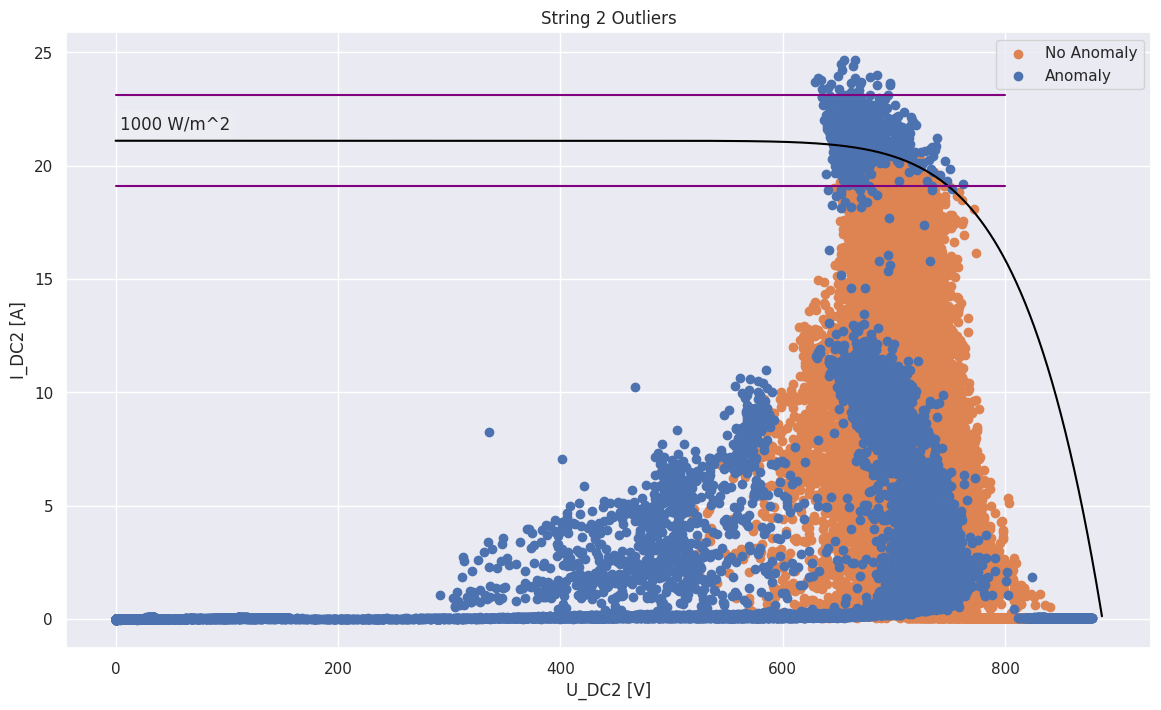

In [114]:
plt.figure(figsize=(14, 8))
x = np.arange(0.01,887.4,1)
y = -7084864.500*np.exp(-11291.87/x)+21.10

plt.plot(x, y, 'r', color='black')
plt.scatter(no_anomaly_ae['U_DC2'], no_anomaly_ae['I_DC2'], label='No Anomaly',color='#dd8452')
plt.scatter(anomaly_ae['U_DC2'], anomaly_ae['I_DC2'], label='Anomaly',color= '#4c72b0')
plt.xlabel('U_DC2 [V]')
plt.ylabel('I_DC2 [A]')
plt.legend()
plt.title('String 2 Outliers')

plt.annotate('1000 W/m^2', xy=(0.1, 0.85), xycoords='axes fraction',
             fontsize=12, ha='center', va='center',
             bbox=dict(boxstyle='round', alpha=0.1, facecolor='white'))

upper_limit_idc = 21.1 + 2
lower_limit_idc = 21.1 - 2

upper_idc_xaxis =  np.arange(0,900,100)
upper_idc_yaxis = upper_limit_idc*np.ones(upper_idc_xaxis.shape[0])

lower_idc_xaxis =  np.arange(0,900,100)
lower_idc_yaxis = lower_limit_idc*np.ones(lower_idc_xaxis.shape[0])


plt.plot(upper_idc_xaxis, upper_idc_yaxis, 'r', color='purple')
plt.plot(lower_idc_xaxis, lower_idc_yaxis, 'r', color='purple')

In [115]:
sc_fault2 = ae_df[(ae_df['Anomaly'] == 1) & (ae_df['I_DC2']>=lower_limit_idc) & (ae_df['I_DC2']<=upper_limit_idc)]

In [116]:
sc_fault2.shape

(1003, 11)

In [117]:
index_sc2 = sc_fault2.index

In [118]:
ae_df.loc[index_sc2,'Anomaly_String2'] = 'Short Circuit'

In [119]:
ae_df[ae_df['Anomaly_String2'] == 'Short Circuit']

,Timestamp,U_DC1,U_DC2,I_DC1,I_DC2,Anomaly,Label,Anomaly_String1,Anomaly_String2,P_DC1,P_DC2
639,2019-08-07 11:15:00,680.792,687.284,20.836,20.948,1,No Fault,Short Circuit,Short Circuit,14184.982112,14397.225232
641,2019-08-07 11:25:00,693.494,689.792,19.912,20.514,1,No Fault,Short Circuit,Short Circuit,13808.852528,14150.393088
669,2019-08-07 13:45:00,701.630,696.212,20.178,21.078,1,No Fault,Short Circuit,Short Circuit,14157.490140,14674.756536
794,2019-08-08 12:25:00,683.550,685.944,20.950,20.928,1,No Fault,Short Circuit,Short Circuit,14320.372500,14355.436032
795,2019-08-08 12:30:00,679.078,676.326,20.824,20.830,1,No Fault,Short Circuit,Short Circuit,14141.120272,14087.870580
...,...,...,...,...,...,...,...,...,...,...,...
149136,2023-05-24 12:15:00,682.942,681.218,21.268,21.378,1,No Fault,Short Circuit,Short Circuit,14524.810456,14563.078404
149137,2023-05-24 12:20:00,669.718,659.056,22.264,21.968,1,No Fault,Short Circuit,Short Circuit,14910.601552,14478.142208
149844,2023-05-29 11:55:00,690.190,687.906,20.644,20.632,1,No Fault,Short Circuit,Short Circuit,14248.282360,14192.876592
150119,2023-05-31 11:05:00,690.784,682.082,19.938,20.456,1,No Fault,Short Circuit,Short Circuit,13772.851392,13952.669392


No hay fallas de corto circuito

### CIRCUITO ABIERTO

Todas aquellas fallas cuya corriente sea igual a 0

/tmp/ipykernel_4208/2987542991.py:5: UserWarning: color is redundantly defined by the 'color' keyword argument and the fmt string "r" (-> color=(0.7686274509803922, 0.3058823529411765, 0.3215686274509804, 1)). The keyword argument will take precedence.
  plt.plot(x, y, 'r', color='black')
/tmp/ipykernel_4208/2987542991.py:21: UserWarning: color is redundantly defined by the 'color' keyword argument and the fmt string "r" (-> color=(0.7686274509803922, 0.3058823529411765, 0.3215686274509804, 1)). The keyword argument will take precedence.
  plt.plot(voltage_zeros, current, 'r', color='purple')


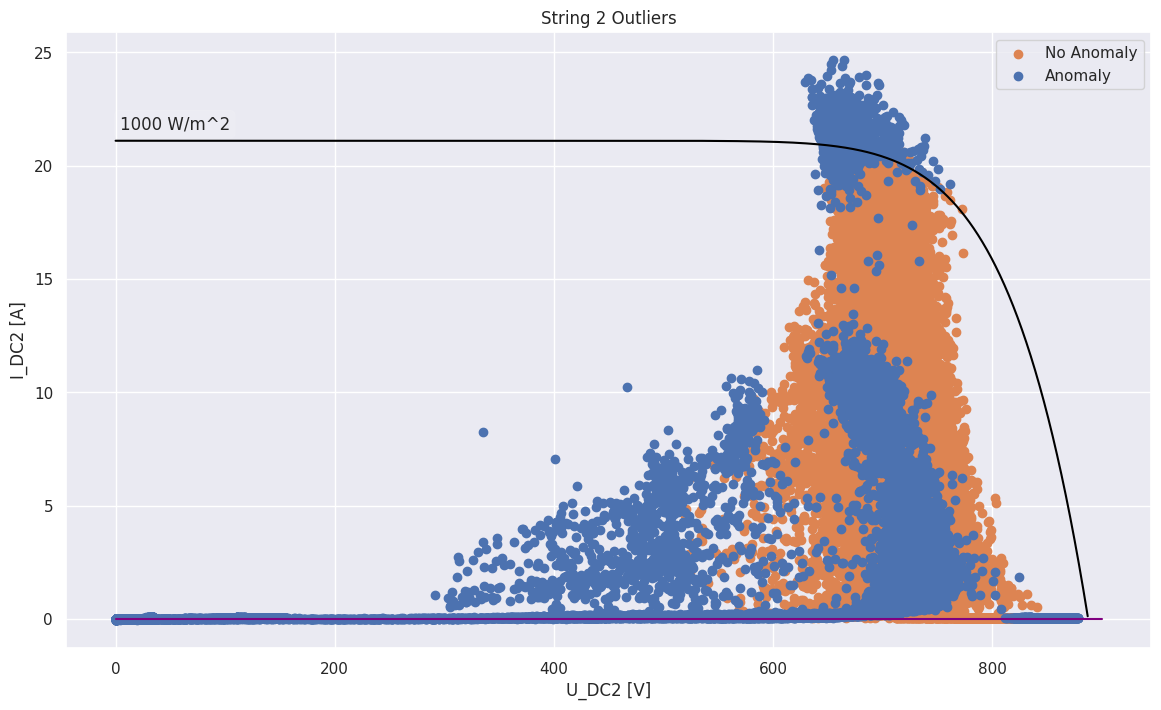

In [120]:
plt.figure(figsize=(14, 8))
x = np.arange(0.01,887.4,1)
y = -7084864.500*np.exp(-11291.87/x)+21.10

plt.plot(x, y, 'r', color='black')
plt.scatter(no_anomaly_ae['U_DC2'], no_anomaly_ae['I_DC2'], label='No Anomaly',color='#dd8452')
plt.scatter(anomaly_ae['U_DC2'], anomaly_ae['I_DC2'], label='Anomaly',color= '#4c72b0')
plt.xlabel('U_DC2 [V]')
plt.ylabel('I_DC2 [A]')
plt.legend()
plt.title('String 2 Outliers')

plt.annotate('1000 W/m^2', xy=(0.1, 0.85), xycoords='axes fraction',
             fontsize=12, ha='center', va='center',
             bbox=dict(boxstyle='round', alpha=0.1, facecolor='white'))

current = np.zeros(10)
voltage_zeros = np.arange(0,1000,100)


plt.plot(voltage_zeros, current, 'r', color='purple')

In [121]:
oc_fault2 = ae_df[(ae_df['Anomaly'] == 1) & (ae_df['I_DC2']==0) & (ae_df['U_DC2']!=0)]

In [122]:
oc_fault2.shape

(14, 11)

In [123]:
index_oc2 = oc_fault2.index

In [124]:
ae_df.loc[index_oc2,'Anomaly_String2'] = 'Open Circuit'

In [125]:
ae_df[(ae_df['Anomaly_String2'] == 'Open Circuit')]

,Timestamp,U_DC1,U_DC2,I_DC1,I_DC2,Anomaly,Label,Anomaly_String1,Anomaly_String2,P_DC1,P_DC2
16543,2019-11-28 05:45:00,1.262,1.270,0.000,0.0,1,No Fault,Open Circuit,Open Circuit,0.000000,0.0
19660,2019-12-20 06:00:00,0.642,0.646,0.000,0.0,1,No Fault,Open Circuit,Open Circuit,0.000000,0.0
23701,2020-01-18 06:05:00,0.730,0.734,0.000,0.0,1,No Fault,Open Circuit,Open Circuit,0.000000,0.0
37189,2020-04-24 05:45:00,1.192,1.198,0.000,0.0,1,No Fault,Open Circuit,Open Circuit,0.000000,0.0
45305,2020-06-20 05:40:00,0.798,0.802,0.000,0.0,1,No Fault,Open Circuit,Open Circuit,0.000000,0.0
47719,2020-07-07 05:50:00,1.000,1.006,0.000,0.0,1,No Fault,Open Circuit,Open Circuit,0.000000,0.0
61567,2020-10-13 05:50:00,1.414,1.420,0.000,0.0,1,No Fault,Open Circuit,Open Circuit,0.000000,0.0
91943,2021-05-19 05:45:00,128.377,128.560,0.058,0.0,1,No Fault,Shading,Open Circuit,7.445866,0.0
119906,2022-04-01 06:00:00,59.167,11.820,0.094,0.0,1,No Fault,Shading,Open Circuit,5.561698,0.0
121011,2022-04-09 06:00:00,131.725,17.010,0.050,0.0,1,No Fault,Shading,Open Circuit,6.586250,0.0


In [126]:
ae_df

,Timestamp,U_DC1,U_DC2,I_DC1,I_DC2,Anomaly,Label,Anomaly_String1,Anomaly_String2,P_DC1,P_DC2
0,2019-08-02 16:25:00,777.010,768.710,2.700,2.607,0,No Fault,No Fault,No Fault,2097.927000,2004.026970
1,2019-08-02 16:30:00,761.130,745.964,3.862,3.748,0,No Fault,No Fault,No Fault,2939.484060,2795.873072
2,2019-08-02 16:35:00,736.754,742.908,3.228,3.192,0,No Fault,No Fault,No Fault,2378.241912,2371.362336
3,2019-08-02 16:40:00,731.928,732.224,2.568,2.484,0,No Fault,No Fault,No Fault,1879.591104,1818.844416
4,2019-08-02 16:45:00,723.546,720.698,1.654,1.640,0,No Fault,No Fault,No Fault,1196.745084,1181.944720
...,...,...,...,...,...,...,...,...,...,...,...
150393,2023-06-02 10:10:00,712.860,698.410,15.514,15.758,0,No Fault,No Fault,No Fault,11059.310040,11005.544780
150394,2023-06-02 10:15:00,703.810,696.148,16.136,16.278,0,No Fault,No Fault,No Fault,11356.678160,11331.897144
150395,2023-06-02 10:20:00,702.586,466.782,16.520,10.250,1,No Fault,No Fault,Shading,11606.720720,4784.515500
150396,2023-06-02 10:25:00,703.080,32.316,15.754,0.080,1,No Fault,No Fault,Shading,11076.322320,2.585280


### FALLA NO IDENTIFICADA

/tmp/ipykernel_4208/857660959.py:5: UserWarning: color is redundantly defined by the 'color' keyword argument and the fmt string "r" (-> color=(0.7686274509803922, 0.3058823529411765, 0.3215686274509804, 1)). The keyword argument will take precedence.
  plt.plot(x, y, 'r', color='black')
/tmp/ipykernel_4208/857660959.py:27: UserWarning: color is redundantly defined by the 'color' keyword argument and the fmt string "r" (-> color=(0.7686274509803922, 0.3058823529411765, 0.3215686274509804, 1)). The keyword argument will take precedence.
  plt.plot(upper_idc_xaxis, upper_idc_yaxis, 'r', color='purple')


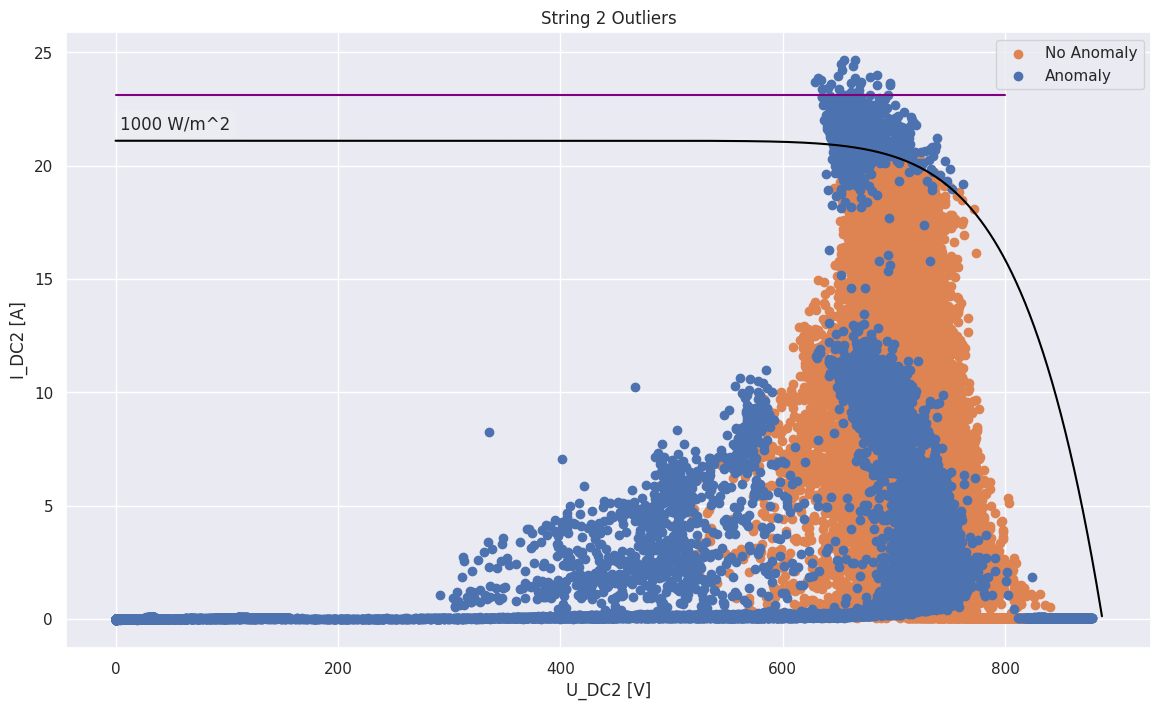

In [127]:
plt.figure(figsize=(14, 8))
x = np.arange(0.01,887.4,1)
y = -7084864.500*np.exp(-11291.87/x)+21.10

plt.plot(x, y, 'r', color='black')
plt.scatter(no_anomaly_ae['U_DC2'], no_anomaly_ae['I_DC2'], label='No Anomaly',color='#dd8452')
plt.scatter(anomaly_ae['U_DC2'], anomaly_ae['I_DC2'], label='Anomaly',color= '#4c72b0')
plt.xlabel('U_DC2 [V]')
plt.ylabel('I_DC2 [A]')
plt.legend()
plt.title('String 2 Outliers')

plt.annotate('1000 W/m^2', xy=(0.1, 0.85), xycoords='axes fraction',
             fontsize=12, ha='center', va='center',
             bbox=dict(boxstyle='round', alpha=0.1, facecolor='white'))

upper_limit_idc = 21.1 + 2
lower_limit_idc = 21.1 - 2

upper_idc_xaxis =  np.arange(0,900,100)
upper_idc_yaxis = upper_limit_idc*np.ones(upper_idc_xaxis.shape[0])

lower_idc_xaxis =  np.arange(0,900,100)
lower_idc_yaxis = lower_limit_idc*np.ones(lower_idc_xaxis.shape[0])


plt.plot(upper_idc_xaxis, upper_idc_yaxis, 'r', color='purple')

In [128]:
unknown_2 = ae_df[(ae_df['Anomaly'] == 1) & (ae_df['I_DC2']>=upper_limit_idc)]

In [129]:
index_u2 = unknown_2.index

In [130]:
ae_df.loc[index_u2,'Anomaly_String2'] = 'Unknown'

In [131]:
ae_df[(ae_df['Anomaly_String2'] == 'Unknown')]

,Timestamp,U_DC1,U_DC2,I_DC1,I_DC2,Anomaly,Label,Anomaly_String1,Anomaly_String2,P_DC1,P_DC2
9033,2019-10-06 11:50:00,721.414,685.026,19.998,24.020,1,No Fault,Short Circuit,Unknown,14426.837172,16454.324520
9034,2019-10-06 11:55:00,698.836,669.122,20.810,23.596,1,No Fault,Short Circuit,Unknown,14542.777160,15788.602712
11766,2019-10-25 12:20:00,727.352,678.180,19.984,23.924,1,No Fault,Short Circuit,Unknown,14535.402368,16224.778320
11767,2019-10-25 12:25:00,688.700,661.026,21.424,23.666,1,No Fault,Short Circuit,Unknown,14754.708800,15643.841316
14054,2019-11-10 11:45:00,709.344,654.788,20.538,24.662,1,No Fault,Short Circuit,Unknown,14568.507072,16148.381656
18315,2019-12-10 11:25:00,660.246,649.214,22.368,23.964,1,No Fault,Short Circuit,Unknown,14768.382528,15557.764296
18316,2019-12-10 11:30:00,656.156,662.478,22.420,23.152,1,No Fault,Short Circuit,Unknown,14711.017520,15337.690656
19017,2019-12-15 11:05:00,682.290,668.416,21.570,23.338,1,No Fault,Short Circuit,Unknown,14716.995300,15599.492608
23355,2020-01-15 11:45:00,651.858,643.526,23.112,23.608,1,No Fault,Unknown,Unknown,15065.742096,15192.361808
23359,2020-01-15 12:05:00,711.740,652.504,20.838,24.470,1,No Fault,Short Circuit,Unknown,14831.238120,15966.772880


## ETIQUETADO GENERAL

In [132]:
conditions = [
    ((ae_df['Anomaly_String1'] == 'Unknown') | (ae_df['Anomaly_String2'] == 'Unknown')),
    ((ae_df['Anomaly_String1'] == 'Open Circuit') | (ae_df['Anomaly_String2'] == 'Open Circuit')),
    ((ae_df['Anomaly_String1'] == 'Short Circuit') | (ae_df['Anomaly_String2'] == 'Short Circuit')),
    ((ae_df['Anomaly_String1'] == 'Shading') | (ae_df['Anomaly_String2'] == 'Shading'))
]

choices = ['Unknown', 'Open Circuit', 'Short Circuit', 'Shading']

ae_df['Label'] = np.select(conditions, choices, default='No Fault')

In [133]:
no_fault = ae_df[ae_df['Label']=='No Fault']
shading = ae_df[ae_df['Label']=='Shading']
short_circuit = ae_df[ae_df['Label']=='Short Circuit']
open_circuit = ae_df[ae_df['Label']=='Open Circuit']
unknown = ae_df[ae_df['Label']=='Unknown']

/tmp/ipykernel_4208/2627728045.py:5: UserWarning: color is redundantly defined by the 'color' keyword argument and the fmt string "r" (-> color=(0.7686274509803922, 0.3058823529411765, 0.3215686274509804, 1)). The keyword argument will take precedence.
  plt.plot(x, y, 'r', color='black')


Text(0.1, 0.85, '1000 W/m^2')

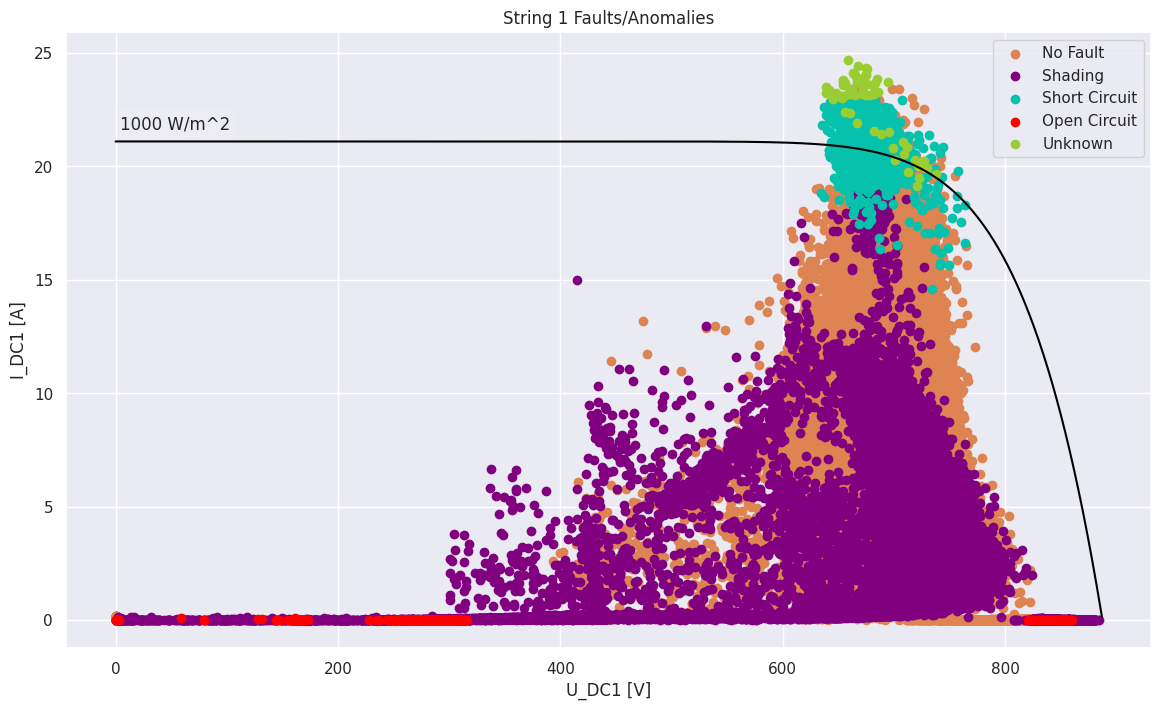

In [134]:
x = np.arange(0.01,887.4,1)
y = -7084864.500*np.exp(-11291.87/x)+21.10

plt.figure(figsize=(14, 8))
plt.plot(x, y, 'r', color='black')
plt.scatter(no_fault['U_DC1'], no_fault['I_DC1'], label='No Fault',color='#dd8452')
plt.scatter(shading['U_DC1'], shading['I_DC1'], label='Shading',color='purple')
plt.scatter(short_circuit['U_DC1'], short_circuit['I_DC1'], label='Short Circuit',color= '#06c2ac')
plt.scatter(open_circuit['U_DC1'], open_circuit['I_DC1'], label='Open Circuit',color='red')
plt.scatter(unknown['U_DC1'], unknown['I_DC1'], label='Unknown',color='yellowgreen')
plt.xlabel('U_DC1 [V]')
plt.ylabel('I_DC1 [A]')
plt.legend()
plt.title('String 1 Faults/Anomalies')

plt.annotate('1000 W/m^2', xy=(0.1, 0.85), xycoords='axes fraction',
             fontsize=12, ha='center', va='center',
             bbox=dict(boxstyle='round', alpha=0.1, facecolor='white'))


/tmp/ipykernel_4208/1713161133.py:5: UserWarning: color is redundantly defined by the 'color' keyword argument and the fmt string "r" (-> color=(0.7686274509803922, 0.3058823529411765, 0.3215686274509804, 1)). The keyword argument will take precedence.
  plt.plot(x, y, 'r', color='black')


Text(0.1, 0.85, '1000 W/m^2')

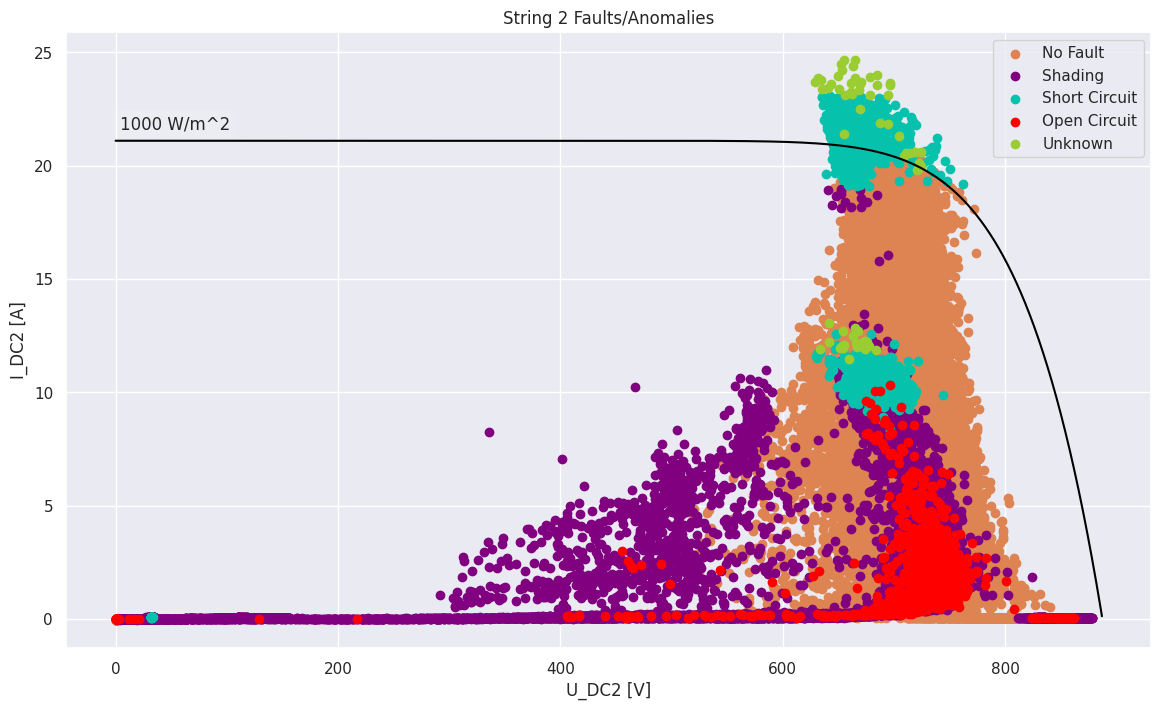

In [135]:
x = np.arange(0.01,887.4,1)
y = -7084864.500*np.exp(-11291.87/x)+21.10

plt.figure(figsize=(14, 8))
plt.plot(x, y, 'r', color='black')
plt.scatter(no_fault['U_DC2'], no_fault['I_DC2'], label='No Fault',color='#dd8452')
plt.scatter(shading['U_DC2'], shading['I_DC2'], label='Shading',color='purple')
plt.scatter(short_circuit['U_DC2'], short_circuit['I_DC2'], label='Short Circuit',color= '#06c2ac')
plt.scatter(open_circuit['U_DC2'], open_circuit['I_DC2'], label='Open Circuit',color='red')
plt.scatter(unknown['U_DC2'], unknown['I_DC2'], label='Unknown',color='yellowgreen')
plt.xlabel('U_DC2 [V]')
plt.ylabel('I_DC2 [A]')
plt.legend()
plt.title('String 2 Faults/Anomalies')

plt.annotate('1000 W/m^2', xy=(0.1, 0.85), xycoords='axes fraction',
             fontsize=12, ha='center', va='center',
             bbox=dict(boxstyle='round', alpha=0.1, facecolor='white'))


## ANÁLISIS DE ETIQUETADO

In [136]:
labeled_df = ae_df[['Timestamp','U_DC1','U_DC2','I_DC1','I_DC2','Label']]

/tmp/ipykernel_4208/2064684990.py:10: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_yticklabels(ax.get_yticks()/1000)


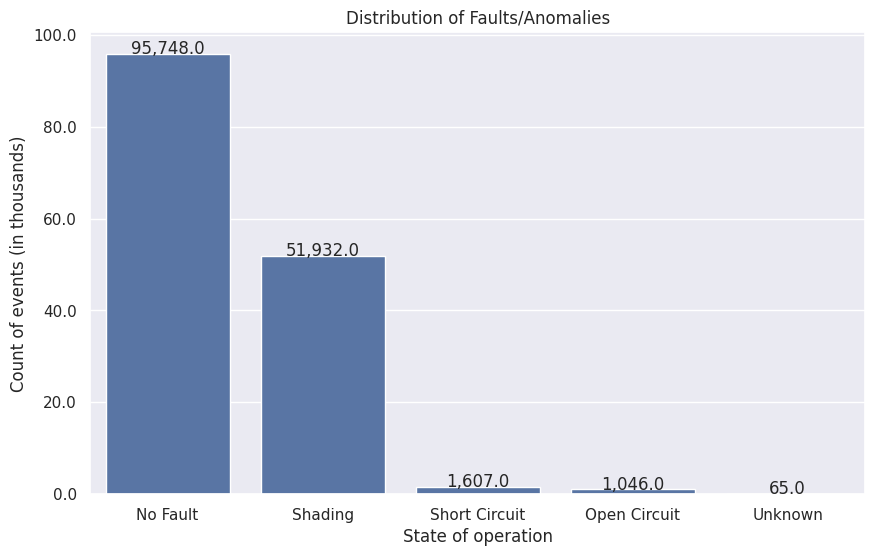

In [137]:
plt.figure(figsize=(10, 6))

# Calculate counts and sort in descending order
order =labeled_df['Label'].value_counts().index
ax = sns.countplot(x='Label',data=labeled_df,order=order)
plt.title('Distribution of Faults/Anomalies')
plt.xlabel('State of operation')
plt.ylabel('Count of events (in thousands)')

ax.set_yticklabels(ax.get_yticks()/1000)

for p in ax.patches:
    height = p.get_height()
    ax.text(x = p.get_x()+(p.get_width()/2),
            y = height+0.2,
            s = '{:,}'.format(height),  # Original value here
            ha = 'center')

plt.show()

In [138]:
order

Index(['No Fault', 'Shading', 'Short Circuit', 'Open Circuit', 'Unknown'], dtype='object', name='Label')

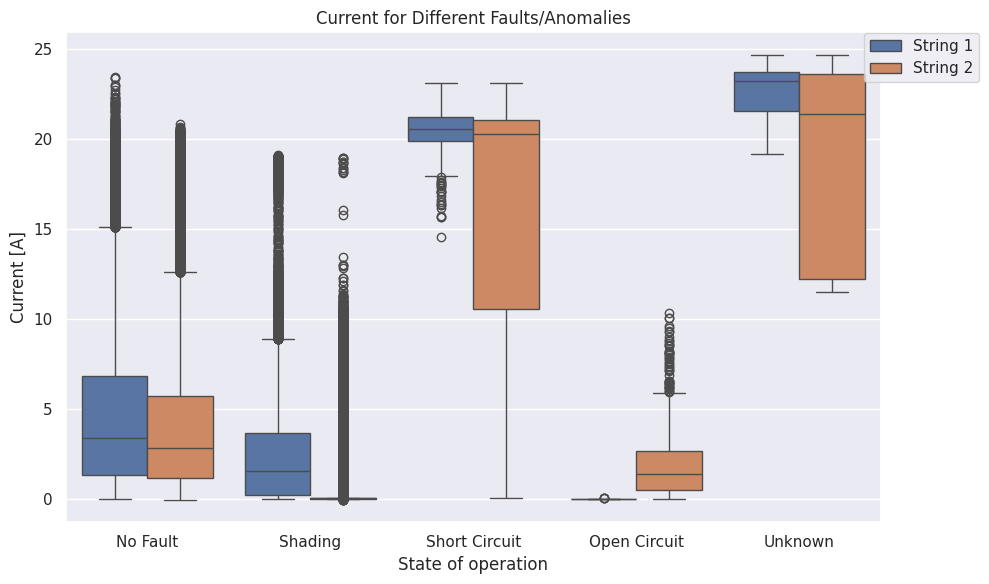

In [139]:
# Create a new dataframe
ae_df_new = pd.concat([
    ae_df[['Label', 'I_DC1']].rename(columns={'I_DC1': 'Current'}).assign(String='String 1'),
    ae_df[['Label', 'I_DC2']].rename(columns={'I_DC2': 'Current'}).assign(String='String 2')
])

plt.figure(figsize=(10, 6))
ax =sns.boxplot(x='Label', y='Current', hue='String', data=ae_df_new)
ax.legend(loc='upper right', bbox_to_anchor=(1.13,1.015))
plt.title('Current for Different Faults/Anomalies')
plt.xlabel('State of operation')
plt.ylabel('Current [A]')

plt.tight_layout()
plt.show()

In [140]:
ae_df_new[(ae_df_new['Label']=='Shading') & (ae_df_new['String']=='String 2')]

,Label,Current,String
15,Shading,0.056,String 2
16,Shading,0.084,String 2
17,Shading,0.122,String 2
18,Shading,0.192,String 2
19,Shading,0.280,String 2
...,...,...,...
150341,Shading,0.122,String 2
150342,Shading,0.202,String 2
150395,Shading,10.250,String 2
150396,Shading,0.080,String 2


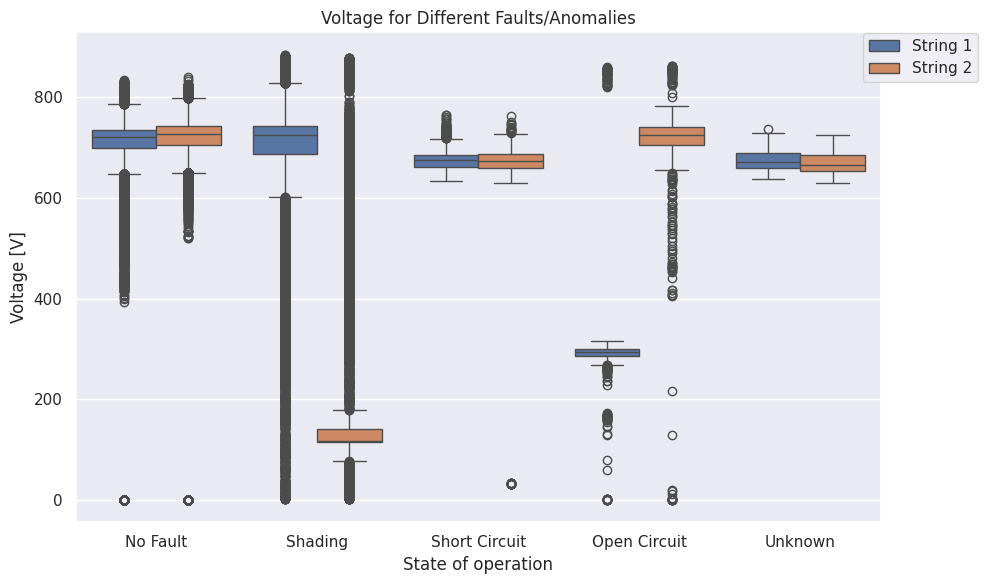

In [141]:
# Create a new dataframe
ae_df_new = pd.concat([
    ae_df[['Label', 'U_DC1']].rename(columns={'U_DC1': 'Voltage'}).assign(String='String 1'),
    ae_df[['Label', 'U_DC2']].rename(columns={'U_DC2': 'Voltage'}).assign(String='String 2')
])

plt.figure(figsize=(10, 6))
ax = sns.boxplot(x='Label', y='Voltage', hue='String', data=ae_df_new)
ax.legend(loc='upper right', bbox_to_anchor=(1.13,1.015))
plt.title('Voltage for Different Faults/Anomalies')
plt.xlabel('State of operation')
plt.ylabel('Voltage [V]')

plt.tight_layout()
plt.show()

In [163]:
labeled_df.to_csv('df_with_labels_ae_new.csv', sep=';', index=False, encoding='utf-8')